# TUGAS P17 - P18 Ekstraksi Fitur Global dan Content-Based Image Retrieval (CBIR)

### Nama: Faruqi Akbar
### NIM : 245150207111003

In [30]:
import os
import cv2
import numpy as np
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt

In [31]:
drive.mount("/content/drive")
dataset_path = "/content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset"

print("Lokasi:", dataset_path)

print("\nDaftar file:")
for nama_file in sorted(os.listdir(dataset_path)):
    print("-", nama_file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lokasi: /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset

Daftar file:
- database_fitur_global.csv
- db_1_4tomat_merah.jpg
- db_2_tomat_kuning.jpg
- db_3_tomat_6buah.jpg
- db_4_tomat_oren.jpeg
- db_5_tomat_merah_hijau.jpg
- hasil_ranking_cbir.csv
- hasil_segmentasi
- query_1_tomat_merah_mengkilat.jpg
- query_2_tomat_kuning_kecil.jpeg
- query_fitur_global.csv


# 1. Mempersiapkan Citra

In [32]:
# 1.1 MEMBACA DATASET 5 CITRA & 2 CITRA QUERY

database_files = [
    "db_1_4tomat_merah.jpg",
    "db_2_tomat_kuning.jpg",
    "db_3_tomat_6buah.jpg",
    "db_4_tomat_oren.jpeg",
    "db_5_tomat_merah_hijau.jpg"
]

query_files = [
    "query_1_tomat_merah_mengkilat.jpg",
    "query_2_tomat_kuning_kecil.jpeg"
]

semua_files = database_files + query_files

images = {}

for nama_file in semua_files:

    path = os.path.join(dataset_path, nama_file)
    img = cv2.imread(path)

    img_rgb = cv2.cvtColor(
        img, cv2.COLOR_BGR2RGB
    )

    images[nama_file] = img_rgb

    print(f"{nama_file} -> {img_rgb.shape}")

print("Jumlah citra database:", len(database_files))
print("Jumlah citra query   :", len(query_files))
print("Total citra          :", len(images))

db_1_4tomat_merah.jpg -> (798, 960, 3)
db_2_tomat_kuning.jpg -> (720, 960, 3)
db_3_tomat_6buah.jpg -> (720, 960, 3)
db_4_tomat_oren.jpeg -> (636, 960, 3)
db_5_tomat_merah_hijau.jpg -> (684, 960, 3)
query_1_tomat_merah_mengkilat.jpg -> (720, 960, 3)
query_2_tomat_kuning_kecil.jpeg -> (636, 960, 3)
Jumlah citra database: 5
Jumlah citra query   : 2
Total citra          : 7


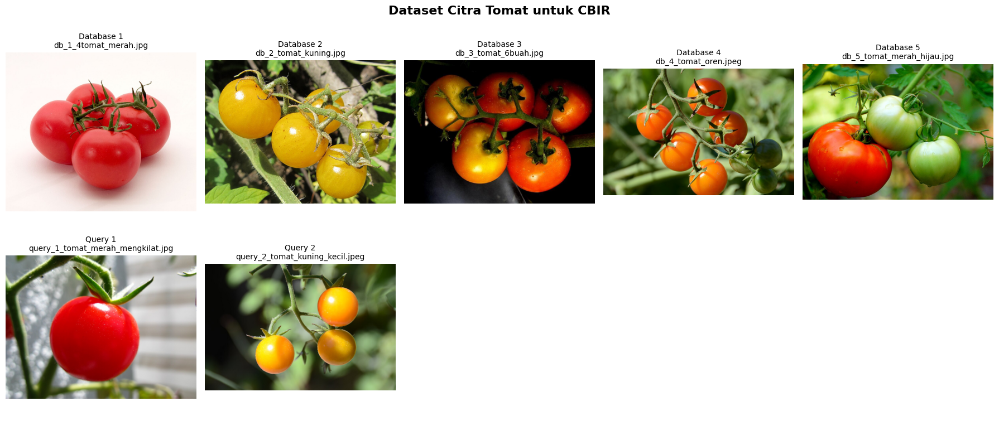

In [33]:
# 1.2 MEM-VISUALISASI 5 DATABASE DAN 2 QUERY

fig, ax = plt.subplots(2, 5, figsize=(18, 8))

for a in ax.flat:
    a.axis("off")

for i, nama_file in enumerate(database_files):

    ax[0, i].imshow(images[nama_file])
    ax[0, i].set_title(
        f"Database {i+1}\n{nama_file}",
        fontsize=10
    )

for i, nama_file in enumerate(query_files):

    ax[1, i].imshow(images[nama_file])
    ax[1, i].set_title(
        f"Query {i+1}\n{nama_file}",
        fontsize=10
    )

plt.suptitle(
    "Dataset Citra Tomat untuk CBIR",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 2. Segmentasi Citra

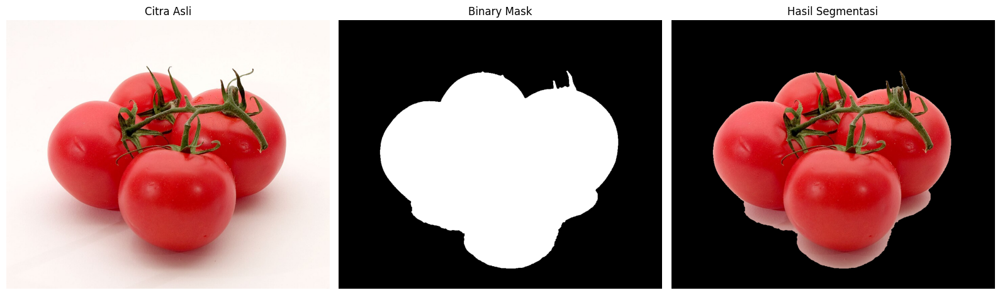

In [34]:
# DB 1: TOMAT MERAH DENGAN BACKGROUND PUTIH

nama_file = "db_1_4tomat_merah.jpg"
img = images[nama_file]

# 1. Konversi RGB ke HSV
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

# 2. Gaussian Blur untuk mengurangi noise
hsv_blur = cv2.GaussianBlur(hsv, (5, 5), 1)

# 3. Deteksi background putih
mask_background = cv2.inRange(
    hsv_blur,
    (0, 0, 170),
    (179, 65, 255)
)

# 4. Invers mask supaya tomat menjadi putih
mask_tomat = cv2.bitwise_not(mask_background)

# 5. Morphological Opening
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

mask_bersih = cv2.morphologyEx(
    mask_tomat,
    cv2.MORPH_OPEN,
    kernel
)

# 6. Morphological Closing
mask_bersih = cv2.morphologyEx(
    mask_bersih,
    cv2.MORPH_CLOSE,
    kernel
)

# 7. Menerapkan mask pada citra asli
hasil_segmentasi = cv2.bitwise_and(
    img,
    img,
    mask=mask_bersih
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img)
ax[0].set_title("Citra Asli")

ax[1].imshow(mask_bersih, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Binary Mask")

ax[2].imshow(hasil_segmentasi)
ax[2].set_title("Hasil Segmentasi")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [35]:
# MENYIMPAN HASIL SEGMENTASI DB 1

segmentation_masks = {}
segmentation_results = {}

segmentation_masks[nama_file] = mask_bersih.copy()
segmentation_results[nama_file] = hasil_segmentasi.copy()

output_dir = os.path.join(dataset_path, "hasil_segmentasi")
os.makedirs(output_dir, exist_ok=True)

path_mask = os.path.join(output_dir, "mask_db1.png")
path_hasil = os.path.join(output_dir, "hasil_segmentasi_db1.png")

cv2.imwrite(path_mask, mask_bersih)

cv2.imwrite(
    path_hasil,
    cv2.cvtColor(hasil_segmentasi, cv2.COLOR_RGB2BGR)
)

print("Binary mask tersimpan:", path_mask)
print("Hasil berwarna tersimpan:", path_hasil)

Binary mask tersimpan: /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_db1.png
Hasil berwarna tersimpan: /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_db1.png


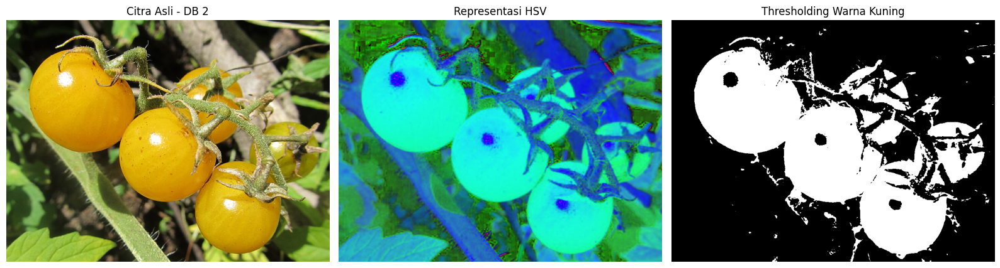

In [36]:
# DB 2: TOMAT KUNING

# Tahap 1: Gaussian Filter dan HSV Thresholding
nama_db2 = "db_2_tomat_kuning.jpg"
img_db2 = images[nama_db2]

# 1. Gaussian Filter untuk mengurangi noise
img_blur_db2 = cv2.GaussianBlur(
    img_db2, (5, 5), 1
)

# 2. Konversi RGB ke HSV
hsv_db2 = cv2.cvtColor(
    img_blur_db2, cv2.COLOR_RGB2HSV
)

# 3. Thresholding warna kuning
batas_bawah = np.array([12, 110, 70])
batas_atas = np.array([30, 255, 255])

mask_awal_db2 = cv2.inRange(
    hsv_db2,
    batas_bawah,
    batas_atas
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_db2)
ax[0].set_title("Citra Asli - DB 2")

ax[1].imshow(hsv_db2)
ax[1].set_title("Representasi HSV")

ax[2].imshow(mask_awal_db2, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Thresholding Warna Kuning")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

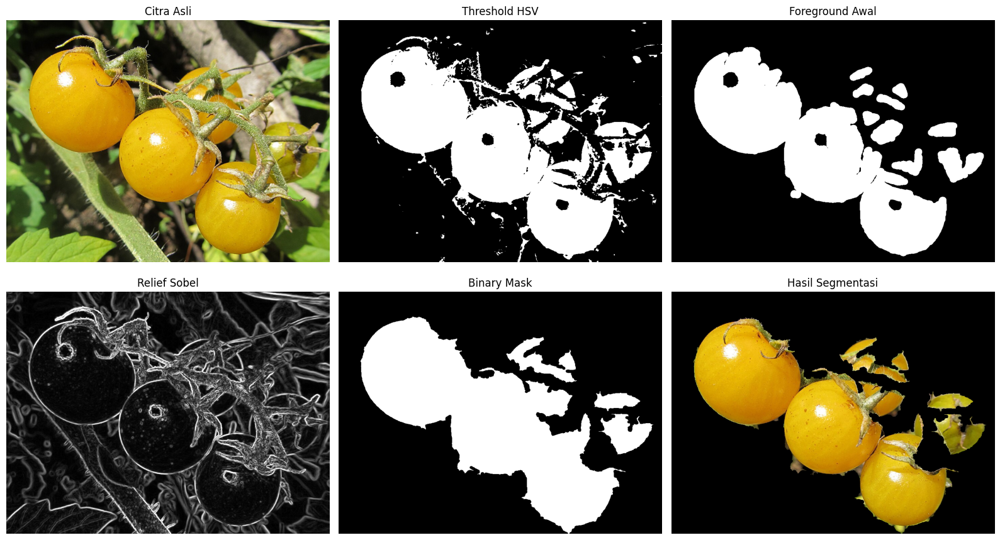

In [37]:
# Tahap 2 - DB 2: Morfologi + Sobel + Watershed

h_db2, w_db2 = mask_awal_db2.shape

# Morphological Opening
kernel_open = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (21, 21)
)

mask_inti = cv2.morphologyEx(
    mask_awal_db2,
    cv2.MORPH_OPEN,
    kernel_open
)

# Mempertahankan region inti
jumlah, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        mask_inti, connectivity=8
    )
)

sure_foreground = np.zeros_like(mask_inti)

for i in range(1, jumlah):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= 1000:
        sure_foreground[labels == i] = 255

# Membuat wilayah kandidat objek
kernel_dilate = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (13, 13)
)

wilayah_kandidat = cv2.dilate(
    mask_awal_db2,
    kernel_dilate,
    iterations=1
)

markers_db2 = np.zeros(
    (h_db2, w_db2), dtype=np.int32
)

markers_db2[wilayah_kandidat == 0] = 1
markers_db2[sure_foreground == 255] = 2

# Menghitung gradien Sobel
gradien_db2 = []

for channel in cv2.split(img_blur_db2):

    gx = cv2.Sobel(
        channel, cv2.CV_32F, 1, 0, ksize=3
    )

    gy = cv2.Sobel(
        channel, cv2.CV_32F, 0, 1, ksize=3
    )

    magnitude = cv2.magnitude(gx, gy)
    gradien_db2.append(magnitude)

relief_db2 = np.max(
    np.array(gradien_db2), axis=0
)

skala = max(np.percentile(relief_db2, 99), 1)

relief_db2 = np.uint8(
    np.clip(relief_db2 / skala * 255, 0, 255)
)

relief_bgr = cv2.cvtColor(
    relief_db2, cv2.COLOR_GRAY2BGR
)

markers_hasil = markers_db2.copy()

cv2.watershed(relief_bgr, markers_hasil)

mask_ws_db2 = np.where(
    markers_hasil == 2,
    255,
    0
).astype(np.uint8)

# Morphological Closing
kernel_close = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (9, 9)
)

mask_close_db2 = cv2.morphologyEx(
    mask_ws_db2,
    cv2.MORPH_CLOSE,
    kernel_close
)

flood = mask_close_db2.copy()

cv2.floodFill(
    flood,
    np.zeros((h_db2 + 2, w_db2 + 2), np.uint8),
    (0, 0),
    255
)

lubang = cv2.bitwise_not(flood)

mask_filled = cv2.bitwise_or(
    mask_close_db2, lubang
)

jumlah, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        mask_filled, connectivity=8
    )
)

mask_final_db2 = np.zeros_like(mask_filled)

for i in range(1, jumlah):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= 1800:
        mask_final_db2[labels == i] = 255

hasil_db2 = cv2.bitwise_and(
    img_db2,
    img_db2,
    mask=mask_final_db2
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar = [
    (img_db2, "Citra Asli", None),
    (mask_awal_db2, "Threshold HSV", "gray"),
    (sure_foreground, "Foreground Awal", "gray"),
    (relief_db2, "Relief Sobel", "gray"),
    (mask_final_db2, "Binary Mask", "gray"),
    (hasil_db2, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar):
    a.imshow(gambar_i, cmap=cmap)
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [38]:
# MENYIMPAN HASIL SEGMENTASI DB 2

segmentation_masks[nama_db2] = mask_final_db2.copy()
segmentation_results[nama_db2] = hasil_db2.copy()

output_dir = os.path.join(dataset_path, "hasil_segmentasi")
os.makedirs(output_dir, exist_ok=True)

path_mask_db2 = os.path.join(output_dir, "mask_db2.png")
path_hasil_db2 = os.path.join(
    output_dir, "hasil_segmentasi_db2.png"
)

simpan_mask = cv2.imwrite(
    path_mask_db2,
    mask_final_db2
)

simpan_hasil = cv2.imwrite(
    path_hasil_db2,
    cv2.cvtColor(hasil_db2, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_db2)
print("Hasil Warna :", path_hasil_db2)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_db2.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_db2.png


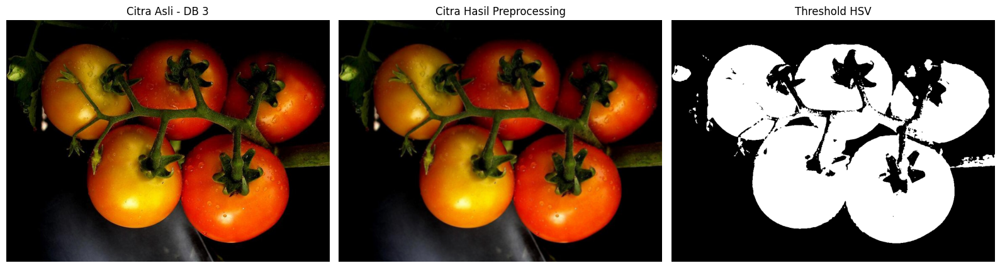

In [39]:
# DB 3: TOMAT MERAH DAN ORANYE

# Tahap 1: Gaussian Filter dan HSV Thresholding
nama_db3 = "db_3_tomat_6buah.jpg"

img_db3 = images[nama_db3]

# 1. Gaussian Filter
img_blur_db3 = cv2.GaussianBlur(
    img_db3, (5, 5), 1
)

hsv_db3 = cv2.cvtColor(
    img_blur_db3, cv2.COLOR_RGB2HSV
)

# Thresholding warna merah, oranye, dan kuning
mask_warna1 = cv2.inRange(
    hsv_db3,
    (0, 70, 55),
    (42, 255, 255)
)

# Rentang merah di ujung Hue
mask_warna2 = cv2.inRange(
    hsv_db3,
    (170, 70, 55),
    (179, 255, 255)
)

mask_awal_db3 = cv2.bitwise_or(
    mask_warna1, mask_warna2
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_db3)
ax[0].set_title("Citra Asli - DB 3")

ax[1].imshow(
    cv2.cvtColor(hsv_db3, cv2.COLOR_HSV2RGB)
)
ax[1].set_title("Citra Hasil Preprocessing")

ax[2].imshow(
    mask_awal_db3,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[2].set_title("Threshold HSV")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

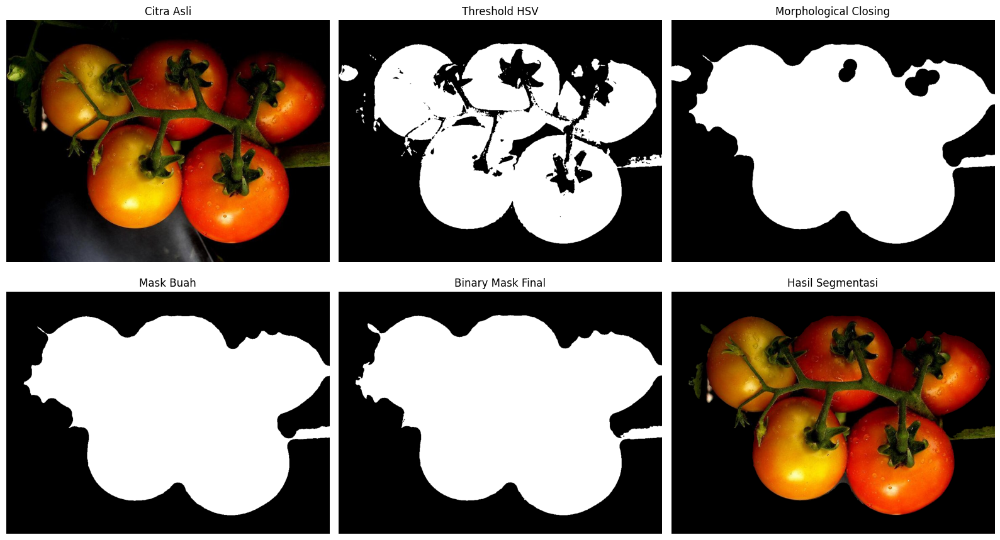

In [40]:
# Tahap 2: Morphological Processing dan Seleksi Kontur

# 1. Closing
kernel_close_db3 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (41, 41)
)

mask_close_db3 = cv2.morphologyEx(
    mask_awal_db3,
    cv2.MORPH_CLOSE,
    kernel_close_db3
)

# Mencari kontur objek
kontur_db3, _ = cv2.findContours(
    mask_close_db3,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Mengambil kontur besar dan mengisi dalamnya
mask_buah_db3 = np.zeros_like(mask_awal_db3)

for kontur in kontur_db3:

    area = cv2.contourArea(kontur)

    if area >= 4000:
        cv2.drawContours(
            mask_buah_db3,
            [kontur],
            -1,
            255,
            thickness=cv2.FILLED
        )

# Thresholding tangkai hijau
mask_tangkai_db3 = cv2.inRange(
    hsv_db3,
    (30, 50, 28),
    (100, 255, 255)
)

# Membatasi tangkai di sekitar area tomat
kernel_dekat = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (31, 31)
)

area_dekat_buah = cv2.dilate(
    mask_buah_db3,
    kernel_dekat,
    iterations=1
)

mask_tangkai_db3 = cv2.bitwise_and(
    mask_tangkai_db3,
    area_dekat_buah
)

kernel_open_db3 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mask_tangkai_db3 = cv2.morphologyEx(
    mask_tangkai_db3,
    cv2.MORPH_OPEN,
    kernel_open_db3
)

mask_gabungan_db3 = cv2.bitwise_or(
    mask_buah_db3,
    mask_tangkai_db3
)

mask_gabungan_db3 = cv2.morphologyEx(
    mask_gabungan_db3,
    cv2.MORPH_CLOSE,
    kernel_open_db3
)

jumlah, labels, stats, _ = cv2.connectedComponentsWithStats(
    mask_gabungan_db3,
    connectivity=8
)

mask_final_db3 = np.zeros_like(mask_gabungan_db3)

for i in range(1, jumlah):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= 1200:
        mask_final_db3[labels == i] = 255

hasil_db3 = cv2.bitwise_and(
    img_db3,
    img_db3,
    mask=mask_final_db3
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar_db3 = [
    (img_db3, "Citra Asli", None),
    (mask_awal_db3, "Threshold HSV", "gray"),
    (mask_close_db3, "Morphological Closing", "gray"),
    (mask_buah_db3, "Mask Buah", "gray"),
    (mask_final_db3, "Binary Mask Final", "gray"),
    (hasil_db3, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar_db3):
    a.imshow(
        gambar_i,
        cmap=cmap,
        vmin=0 if cmap == "gray" else None,
        vmax=255 if cmap == "gray" else None
    )
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [41]:
# MENYIMPAN HASIL SEGMENTASI DB 3

segmentation_masks[nama_db3] = mask_final_db3.copy()
segmentation_results[nama_db3] = hasil_db3.copy()

output_dir = os.path.join(
    dataset_path,
    "hasil_segmentasi"
)

os.makedirs(output_dir, exist_ok=True)

path_mask_db3 = os.path.join(
    output_dir, "mask_db3.png"
)

path_hasil_db3 = os.path.join(
    output_dir, "hasil_segmentasi_db3.png"
)

simpan_mask = cv2.imwrite(
    path_mask_db3,
    mask_final_db3
)

simpan_hasil = cv2.imwrite(
    path_hasil_db3,
    cv2.cvtColor(hasil_db3, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_db3)
print("Hasil Warna :", path_hasil_db3)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_db3.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_db3.png


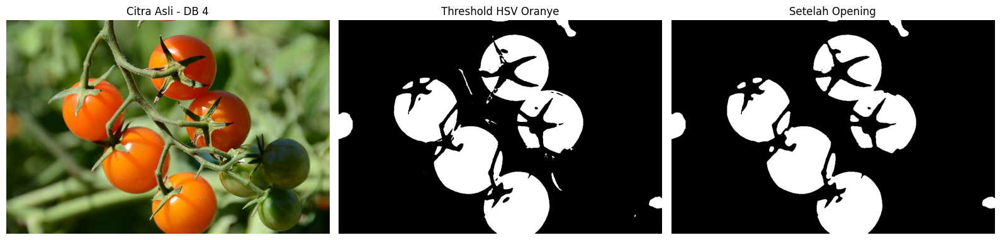

In [42]:
# DB 4 : TOMAT ORANYE DAN HIJAU

# Tahap 1: Gaussian Filter dan HSV Thresholding

nama_db4 = "db_4_tomat_oren.jpeg"

img_db4 = images[nama_db4]

img_blur_db4 = cv2.GaussianBlur(
    img_db4, (7, 7), 3
)

hsv_db4 = cv2.cvtColor(
    img_blur_db4, cv2.COLOR_RGB2HSV
)

mask_oranye_db4 = cv2.inRange(
    hsv_db4,
    (0, 75, 60),
    (25, 255, 255)
)

kernel_open_db4 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (11, 11)
)

mask_open_db4 = cv2.morphologyEx(
    mask_oranye_db4,
    cv2.MORPH_OPEN,
    kernel_open_db4
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_db4)
ax[0].set_title("Citra Asli - DB 4")

ax[1].imshow(mask_oranye_db4, cmap="gray")
ax[1].set_title("Threshold HSV Oranye")

ax[2].imshow(mask_open_db4, cmap="gray")
ax[2].set_title("Setelah Opening")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

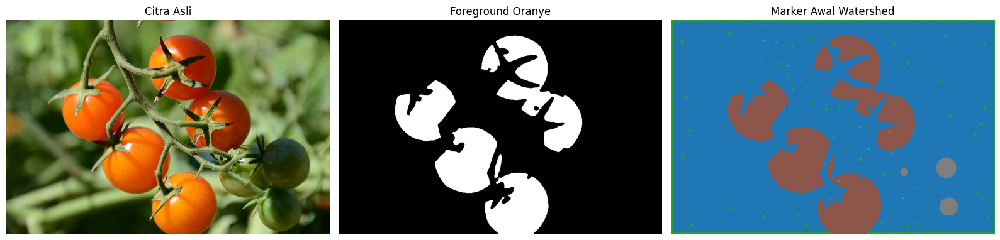

In [43]:
# Tahap 2: Membuat Marker Watershed

h_db4, w_db4 = mask_open_db4.shape

# 1. Mengambil 5 region oranye terbesar
jumlah, labels, stats, _ = cv2.connectedComponentsWithStats(
    mask_open_db4, connectivity=8
)

urutan = sorted(
    range(1, jumlah),
    key=lambda i: stats[i, cv2.CC_STAT_AREA],
    reverse=True
)

label_oranye = urutan[:5]

mask_inti_db4 = np.where(
    np.isin(labels, label_oranye),
    255, 0
).astype(np.uint8)

kernel_inti = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (7, 7)
)

mask_inti_db4 = cv2.erode(
    mask_inti_db4, kernel_inti, iterations=1
)

markers_db4 = np.zeros(
    (h_db4, w_db4), dtype=np.int32
)

markers_db4[:4, :] = 1
markers_db4[-4:, :] = 1
markers_db4[:, :4] = 1
markers_db4[:, -4:] = 1

def titik_db4(x, y):
    return (
        round(x * w_db4 / 960),
        round(y * h_db4 / 636)
    )

def tandai_db4(x, y, radius, label):
    skala = min(w_db4 / 960, h_db4 / 636)
    r = max(1, round(radius * skala))

    cv2.circle(
        markers_db4,
        titik_db4(x, y),
        r, label, -1
    )

background_db4 = [
    (30, 65), (45, 230), (35, 410),
    (60, 610), (175, 560), (275, 585),
    (375, 580), (400, 610), (700, 615),
    (940, 590), (930, 260), (930, 75),
    (660, 75), (700, 130), (800, 180),
    (815, 50), (720, 340), (920, 310),
    (560, 415), (170, 40), (360, 78),
    (55, 330), (410, 60), (420, 250),
    (378, 350), (625, 605), (630, 460),
    (900, 342), (730, 606),
    (325, 130), (348, 165), (360, 206),
    (458, 266), (497, 258), (910, 515),
    (942, 535), (827, 285), (570, 270)
]

for x, y in background_db4:
    tandai_db4(x, y, 4, 1)

markers_db4[mask_inti_db4 == 255] = 2

tomat_hijau_db4 = [
    (815, 440, 30),
    (822, 555, 27),
    (690, 452, 12)
]

for x, y, r in tomat_hijau_db4:
    tandai_db4(x, y, r, 3)

tangkai_db4 = [
    (279, 19), (275, 62), (267, 126),
    (242, 180), (311, 68), (346, 137),
    (381, 180), (392, 244), (334, 260),
    (449, 310), (480, 350), (585, 384),
    (656, 397), (726, 390), (760, 395),
    (730, 500), (688, 530), (495, 480),
    (472, 533), (453, 430), (558, 319),
    (601, 335), (646, 334)
]

for x, y in tangkai_db4:
    tandai_db4(x, y, 2, 4)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_db4)
ax[0].set_title("Citra Asli")

ax[1].imshow(mask_inti_db4, cmap="gray")
ax[1].set_title("Foreground Oranye")

ax[2].imshow(
    markers_db4, cmap="tab10",
    vmin=0, vmax=4
)
ax[2].set_title("Marker Awal Watershed")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

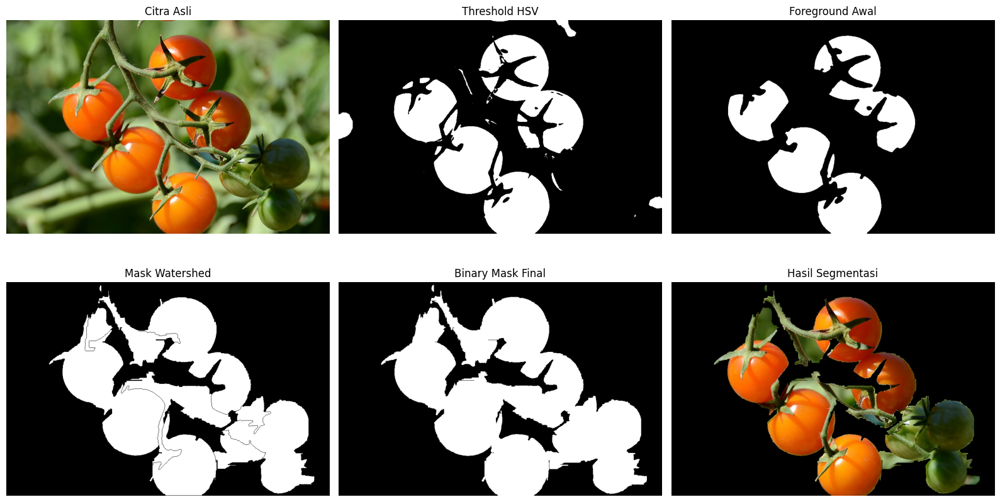

In [44]:
# Tahap 3: Watershed dan Morphological Processing

img_ws_db4 = cv2.cvtColor(
    img_blur_db4,
    cv2.COLOR_RGB2BGR
)

markers_hasil_db4 = markers_db4.copy()

cv2.watershed(
    img_ws_db4,
    markers_hasil_db4
)

# Mengambil seluruh foreground
# Label 2, 3, dan 4
mask_ws_db4 = np.where(
    np.isin(markers_hasil_db4, [2, 3, 4]),
    255, 0
).astype(np.uint8)

kernel_db4 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mask_close_db4 = cv2.morphologyEx(
    mask_ws_db4,
    cv2.MORPH_CLOSE,
    kernel_db4
)

mask_final_db4 = cv2.dilate(
    mask_close_db4,
    kernel_db4,
    iterations=1
)

hasil_db4 = cv2.bitwise_and(
    img_db4,
    img_db4,
    mask=mask_final_db4
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar_db4 = [
    (img_db4, "Citra Asli", None),
    (mask_oranye_db4, "Threshold HSV", "gray"),
    (mask_inti_db4, "Foreground Awal", "gray"),
    (mask_ws_db4, "Mask Watershed", "gray"),
    (mask_final_db4, "Binary Mask Final", "gray"),
    (hasil_db4, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar_db4):
    a.imshow(gambar_i, cmap=cmap)
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [45]:
# MENYIMPAN HASIL SEGMENTASI DB 4

segmentation_masks[nama_db4] = mask_final_db4.copy()
segmentation_results[nama_db4] = hasil_db4.copy()

output_dir = os.path.join(
    dataset_path, "hasil_segmentasi"
)

os.makedirs(output_dir, exist_ok=True)

path_mask_db4 = os.path.join(
    output_dir, "mask_db4.png"
)

path_hasil_db4 = os.path.join(
    output_dir, "hasil_segmentasi_db4.png"
)

simpan_mask = cv2.imwrite(
    path_mask_db4,
    mask_final_db4
)

simpan_hasil = cv2.imwrite(
    path_hasil_db4,
    cv2.cvtColor(hasil_db4, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_db4)
print("Hasil Warna :", path_hasil_db4)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_db4.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_db4.png


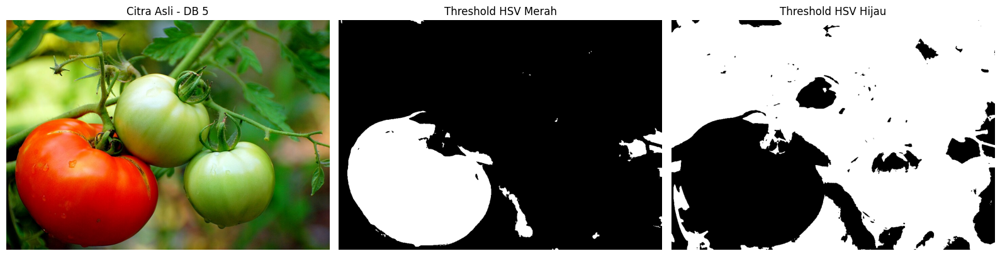

In [46]:
# DB 5 : TOMAT MERAH DAN HIJAU

# Tahap 1: Gaussian Filter dan HSV Thresholding

nama_db5 = "db_5_tomat_merah_hijau.jpg"
img_db5 = images[nama_db5]

img_blur_db5 = cv2.GaussianBlur(
    img_db5, (5, 5), 1
)

hsv_db5 = cv2.cvtColor(
    img_blur_db5, cv2.COLOR_RGB2HSV
)

merah1_db5 = cv2.inRange(
    hsv_db5, (0, 80, 60), (18, 255, 255)
)

merah2_db5 = cv2.inRange(
    hsv_db5, (170, 80, 60), (179, 255, 255)
)

mask_merah_db5 = cv2.bitwise_or(
    merah1_db5, merah2_db5
)

mask_hijau_db5 = cv2.inRange(
    hsv_db5, (25, 35, 45), (95, 255, 255)
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_db5)
ax[0].set_title("Citra Asli - DB 5")

ax[1].imshow(mask_merah_db5, cmap="gray")
ax[1].set_title("Threshold HSV Merah")

ax[2].imshow(mask_hijau_db5, cmap="gray")
ax[2].set_title("Threshold HSV Hijau")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

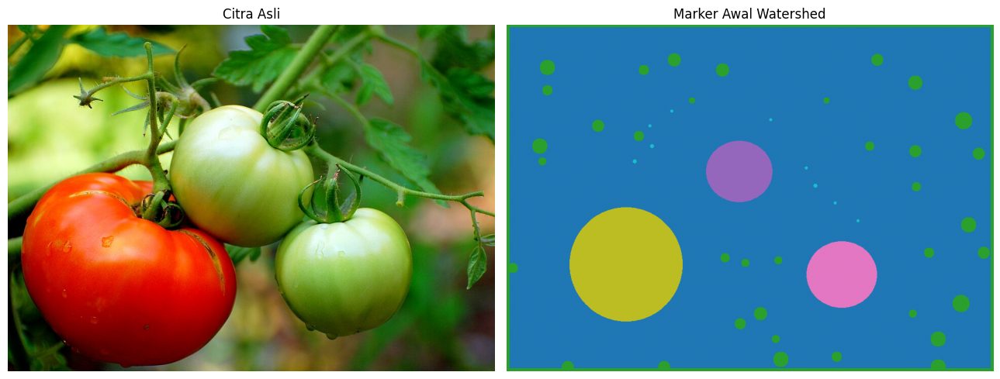

In [47]:
# Tahap 2: Membuat Marker Watershed

h_db5, w_db5 = img_db5.shape[:2]

markers_db5 = np.zeros(
    (h_db5, w_db5), dtype=np.int32
)

sx = w_db5 / 960
sy = h_db5 / 684

def tandai_db5(x, y, radius, label):
    center = (round(x * sx), round(y * sy))
    r = max(1, round(radius * min(sx, sy)))

    cv2.circle(markers_db5, center, r, label, -1)

markers_db5[:6, :] = 1
markers_db5[-6:, :] = 1
markers_db5[:, :6] = 1
markers_db5[:, -6:] = 1

# 2. Marker background
background_db5 = [
    (65, 240, 15), (80, 85, 15),
    (180, 200, 12), (330, 70, 13),
    (425, 90, 13), (730, 70, 12),
    (805, 115, 14), (900, 190, 17),
    (930, 255, 12), (895, 550, 17),
    (850, 620, 15), (850, 675, 15),
    (540, 660, 15), (460, 590, 11),
    (500, 570, 13), (430, 460, 9),
    (470, 470, 8), (310, 675, 12),
    (120, 675, 12), (12, 480, 10),
    (70, 270, 8), (260, 220, 10),
    (270, 90, 10), (80, 130, 10),
    (365, 150, 6), (630, 150, 6),
    (715, 240, 9), (805, 250, 12),
    (807, 320, 9), (832, 450, 10),
    (910, 395, 15), (940, 450, 12),
    (800, 570, 8), (650, 655, 10),
    (530, 620, 8), (535, 465, 8)
]

for x, y, r in background_db5:
    tandai_db5(x, y, r, 1)

# Marker tomat hijau bagian atas
cv2.ellipse(
    markers_db5,
    (round(458*sx), round(290*sy)),
    (round(65*sx), round(60*sy)),
    0, 0, 360, 2, -1
)

# Marker tomat hijau bagian kanan bawah
cv2.ellipse(
    markers_db5,
    (round(660*sx), round(493*sy)),
    (round(69*sx), round(65*sy)),
    0, 0, 360, 3, -1
)

# Marker tomat merah bagian kiri
cv2.ellipse(
    markers_db5,
    (round(235*sx), round(473*sy)),
    (round(111*sx), round(112*sy)),
    0, 0, 360, 4, -1
)

# Marker tangkai
tangkai_db5 = [
    (252, 270, 4), (286, 240, 4),
    (282, 200, 3), (325, 171, 3),
    (520, 188, 3), (590, 283, 3),
    (608, 318, 4), (647, 352, 3),
    (692, 387, 3)
]

for x, y, r in tangkai_db5:
    tandai_db5(x, y, r, 5)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].imshow(img_db5)
ax[0].set_title("Citra Asli")

ax[1].imshow(
    markers_db5,
    cmap="tab10",
    vmin=0,
    vmax=5
)
ax[1].set_title("Marker Awal Watershed")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

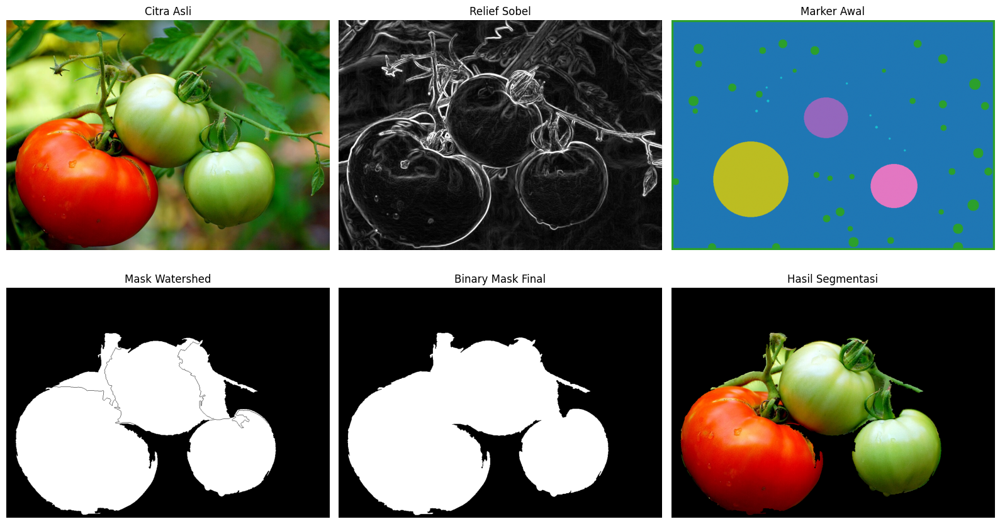

In [48]:
# Tahap 3: Sobel + Watershed + Morphological Processing

img_bgr_db5 = cv2.cvtColor(
    img_blur_db5, cv2.COLOR_RGB2BGR
)

gradien_db5 = []

for channel in cv2.split(img_bgr_db5):

    gx = cv2.Sobel(
        channel, cv2.CV_32F, 1, 0, ksize=3
    )

    gy = cv2.Sobel(
        channel, cv2.CV_32F, 0, 1, ksize=3
    )

    magnitude = cv2.magnitude(gx, gy)
    gradien_db5.append(magnitude)

relief_db5 = np.max(
    np.array(gradien_db5),
    axis=0
)

skala_db5 = max(
    np.percentile(relief_db5, 99), 1
)

relief_db5 = np.uint8(
    np.clip(
        relief_db5 / skala_db5 * 255,
        0, 255
    )
)

relief_bgr_db5 = cv2.cvtColor(
    relief_db5,
    cv2.COLOR_GRAY2BGR
)

markers_hasil_db5 = markers_db5.copy()

cv2.watershed(
    relief_bgr_db5,
    markers_hasil_db5
)

mask_ws_db5 = np.where(
    np.isin(markers_hasil_db5, [2, 3, 4, 5]),
    255,
    0
).astype(np.uint8)

kernel_db5 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mask_close_db5 = cv2.morphologyEx(
    mask_ws_db5,
    cv2.MORPH_CLOSE,
    kernel_db5
)

mask_final_db5 = cv2.dilate(
    mask_close_db5,
    kernel_db5,
    iterations=1
)

hasil_db5 = cv2.bitwise_and(
    img_db5,
    img_db5,
    mask=mask_final_db5
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar_db5 = [
    (img_db5, "Citra Asli", None),
    (relief_db5, "Relief Sobel", "gray"),
    (markers_db5, "Marker Awal", "tab10"),
    (mask_ws_db5, "Mask Watershed", "gray"),
    (mask_final_db5, "Binary Mask Final", "gray"),
    (hasil_db5, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar_db5):
    a.imshow(gambar_i, cmap=cmap)
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [49]:
# MENYIMPAN HASIL SEGMENTASI DB 5

segmentation_masks[nama_db5] = mask_final_db5.copy()
segmentation_results[nama_db5] = hasil_db5.copy()

output_dir = os.path.join(
    dataset_path,
    "hasil_segmentasi"
)

os.makedirs(output_dir, exist_ok=True)

path_mask_db5 = os.path.join(
    output_dir, "mask_db5.png"
)

path_hasil_db5 = os.path.join(
    output_dir, "hasil_segmentasi_db5.png"
)

simpan_mask = cv2.imwrite(
    path_mask_db5,
    mask_final_db5
)

simpan_hasil = cv2.imwrite(
    path_hasil_db5,
    cv2.cvtColor(hasil_db5, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_db5)
print("Hasil Warna :", path_hasil_db5)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_db5.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_db5.png


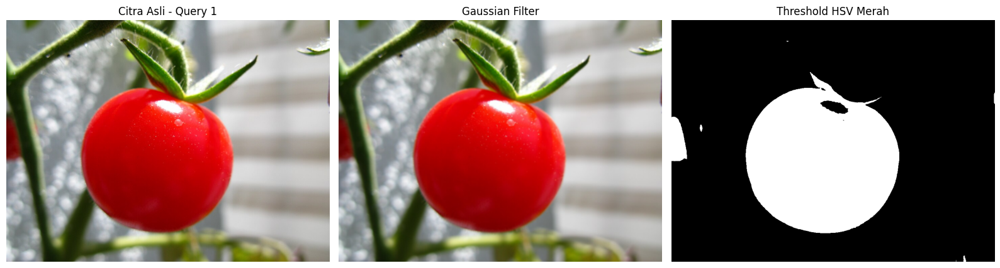

In [50]:
# SEGMENTASI QUERY 1 - TOMAT MERAH MENGKILAT

# Tahap 1: Gaussian Filter dan HSV Thresholding

nama_query1 = "query_1_tomat_merah_mengkilat.jpg"

img_query1 = images[nama_query1]

img_blur_query1 = cv2.GaussianBlur(
    img_query1, (5, 5), 1
)

hsv_query1 = cv2.cvtColor(
    img_blur_query1, cv2.COLOR_RGB2HSV
)

merah1_query1 = cv2.inRange(
    hsv_query1,
    (0, 65, 45),
    (18, 255, 255)
)

merah2_query1 = cv2.inRange(
    hsv_query1,
    (170, 65, 45),
    (179, 255, 255)
)

mask_awal_query1 = cv2.bitwise_or(
    merah1_query1,
    merah2_query1
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_query1)
ax[0].set_title("Citra Asli - Query 1")

ax[1].imshow(img_blur_query1)
ax[1].set_title("Gaussian Filter")

ax[2].imshow(mask_awal_query1, cmap="gray")
ax[2].set_title("Threshold HSV Merah")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

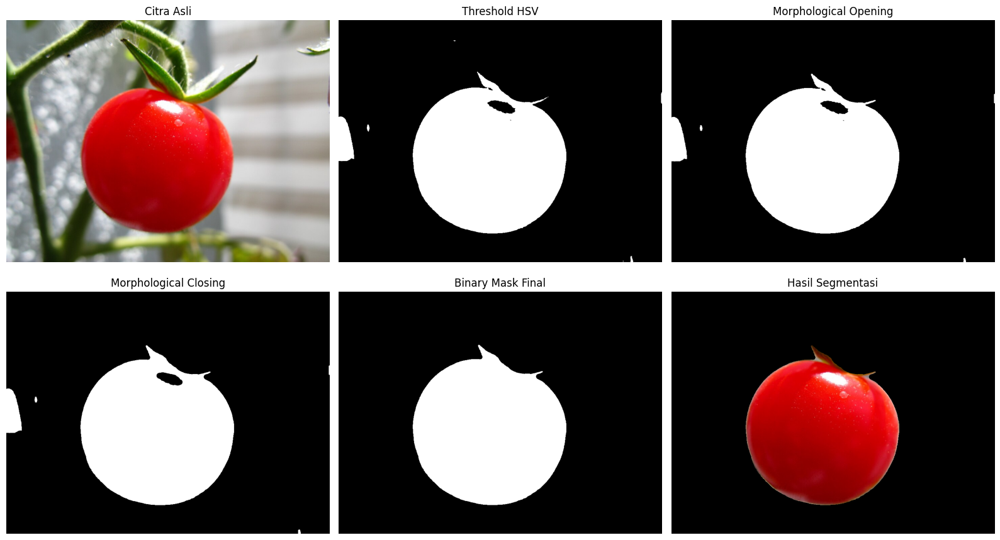

In [51]:
# Tahap 2: Morphological Processing dan Seleksi Kontur

kernel_open_query1 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

mask_open_query1 = cv2.morphologyEx(
    mask_awal_query1,
    cv2.MORPH_OPEN,
    kernel_open_query1
)

kernel_close_query1 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (15, 15)
)

mask_close_query1 = cv2.morphologyEx(
    mask_open_query1,
    cv2.MORPH_CLOSE,
    kernel_close_query1
)

kontur_query1, _ = cv2.findContours(
    mask_close_query1,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

kontur_utama_query1 = max(
    kontur_query1,
    key=cv2.contourArea
)

mask_final_query1 = np.zeros_like(mask_awal_query1)

cv2.drawContours(
    mask_final_query1,
    [kontur_utama_query1],
    -1,
    255,
    thickness=cv2.FILLED
)

hasil_query1 = cv2.bitwise_and(
    img_query1,
    img_query1,
    mask=mask_final_query1
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar_query1 = [
    (img_query1, "Citra Asli", None),
    (mask_awal_query1, "Threshold HSV", "gray"),
    (mask_open_query1, "Morphological Opening", "gray"),
    (mask_close_query1, "Morphological Closing", "gray"),
    (mask_final_query1, "Binary Mask Final", "gray"),
    (hasil_query1, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar_query1):
    a.imshow(gambar_i, cmap=cmap)
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [52]:
# MENYIMPAN HASIL SEGMENTASI QUERY 1

segmentation_masks[nama_query1] = mask_final_query1.copy()
segmentation_results[nama_query1] = hasil_query1.copy()

output_dir = os.path.join(
    dataset_path,
    "hasil_segmentasi"
)

os.makedirs(output_dir, exist_ok=True)

path_mask_query1 = os.path.join(
    output_dir, "mask_query1.png"
)

path_hasil_query1 = os.path.join(
    output_dir, "hasil_segmentasi_query1.png"
)

simpan_mask = cv2.imwrite(
    path_mask_query1,
    mask_final_query1
)

simpan_hasil = cv2.imwrite(
    path_hasil_query1,
    cv2.cvtColor(hasil_query1, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_query1)
print("Hasil Warna :", path_hasil_query1)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_query1.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_query1.png


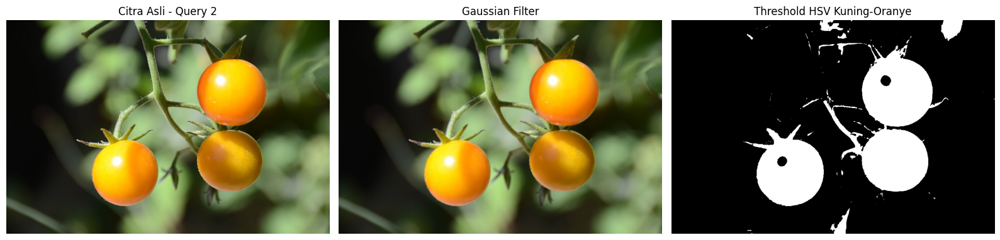

In [53]:
# SEGMENTASI QUERY 2 - TOMAT KUNING KECIL

nama_query2 = "query_2_tomat_kuning_kecil.jpeg"

img_query2 = images[nama_query2]

img_blur_query2 = cv2.GaussianBlur(
    img_query2, (5, 5), 1
)

hsv_query2 = cv2.cvtColor(
    img_blur_query2,
    cv2.COLOR_RGB2HSV
)

batas_bawah_query2 = np.array([5, 85, 65])
batas_atas_query2 = np.array([33, 255, 255])

mask_awal_query2 = cv2.inRange(
    hsv_query2,
    batas_bawah_query2,
    batas_atas_query2
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].imshow(img_query2)
ax[0].set_title("Citra Asli - Query 2")

ax[1].imshow(img_blur_query2)
ax[1].set_title("Gaussian Filter")

ax[2].imshow(
    mask_awal_query2,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[2].set_title("Threshold HSV Kuning-Oranye")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

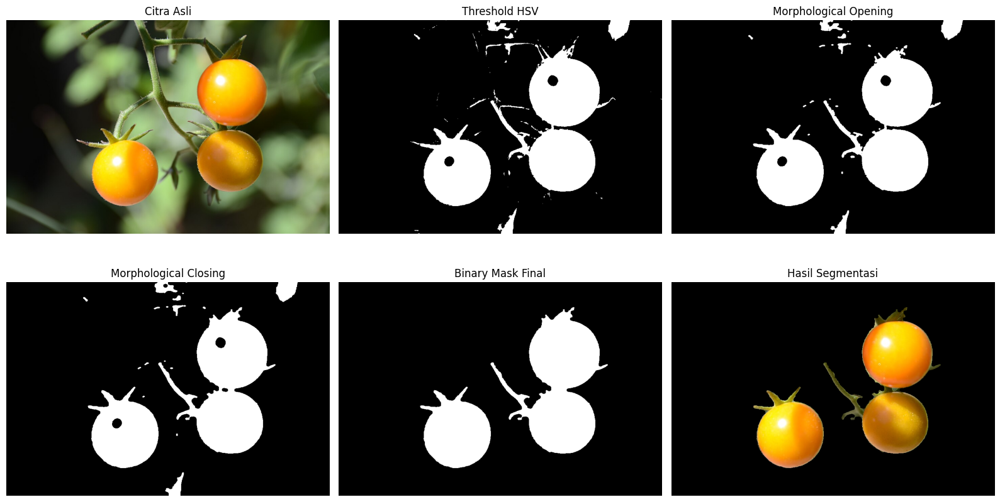

In [54]:
# Tahap 2: Morphological Processing dan Seleksi Kontur

kernel_open_query2 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

mask_open_query2 = cv2.morphologyEx(
    mask_awal_query2,
    cv2.MORPH_OPEN,
    kernel_open_query2
)

kernel_close_query2 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (11, 11)
)

mask_close_query2 = cv2.morphologyEx(
    mask_open_query2,
    cv2.MORPH_CLOSE,
    kernel_close_query2
)

kontur_query2, _ = cv2.findContours(
    mask_close_query2,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

mask_final_query2 = np.zeros_like(
    mask_awal_query2
)

h_query2, w_query2 = mask_awal_query2.shape
min_area_query2 = 4500 * (w_query2 * h_query2) / (960 * 636)

for kontur in kontur_query2:

    area = cv2.contourArea(kontur)

    if area >= min_area_query2:
        cv2.drawContours(
            mask_final_query2,
            [kontur],
            -1,
            255,
            thickness=cv2.FILLED
        )

hasil_query2 = cv2.bitwise_and(
    img_query2,
    img_query2,
    mask=mask_final_query2
)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))

gambar_query2 = [
    (img_query2, "Citra Asli", None),
    (mask_awal_query2, "Threshold HSV", "gray"),
    (mask_open_query2, "Morphological Opening", "gray"),
    (mask_close_query2, "Morphological Closing", "gray"),
    (mask_final_query2, "Binary Mask Final", "gray"),
    (hasil_query2, "Hasil Segmentasi", None)
]

for a, (gambar_i, judul, cmap) in zip(ax.flat, gambar_query2):
    a.imshow(
        gambar_i,
        cmap=cmap,
        vmin=0 if cmap == "gray" else None,
        vmax=255 if cmap == "gray" else None
    )
    a.set_title(judul)
    a.axis("off")

plt.tight_layout()
plt.show()

In [55]:
# MENYIMPAN HASIL SEGMENTASI QUERY 2

segmentation_masks[nama_query2] = mask_final_query2.copy()
segmentation_results[nama_query2] = hasil_query2.copy()

output_dir = os.path.join(
    dataset_path,
    "hasil_segmentasi"
)

os.makedirs(output_dir, exist_ok=True)

path_mask_query2 = os.path.join(
    output_dir,
    "mask_query2.png"
)

path_hasil_query2 = os.path.join(
    output_dir,
    "hasil_segmentasi_query2.png"
)

simpan_mask = cv2.imwrite(
    path_mask_query2,
    mask_final_query2
)

simpan_hasil = cv2.imwrite(
    path_hasil_query2,
    cv2.cvtColor(hasil_query2, cv2.COLOR_RGB2BGR)
)

print("Binary Mask :", path_mask_query2)
print("Hasil Warna :", path_hasil_query2)

Binary Mask : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/mask_query2.png
Hasil Warna : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_segmentasi/hasil_segmentasi_query2.png


# 3. Ekstraksi Fitur Global


### Daftar Fitur Ekstraksi Citra Tomat

| Kelompok | Fitur | Jumlah |
|---|---|---:|
| Warna | Mean RGB (R, G, B) | 3 |
| Warna | Standard Deviation RGB | 3 |
| Warna | Histogram Hue HSV (9 bin) | 9 |
| Bentuk | Area Ratio, Aspect Ratio, Circularity | 3 |
| Tekstur | GLCM Contrast, Homogeneity, Energy | 3 |
| **Total** | | **21 fitur** |

In [56]:
# PERSIAPAN DATA UNTUK EKSTRAKSI FITUR GLOBAL

nama_mask = [
    "mask_db1.png",
    "mask_db2.png",
    "mask_db3.png",
    "mask_db4.png",
    "mask_db5.png",
    "mask_query1.png",
    "mask_query2.png"
]

data_fitur = database_files + query_files

citra_fitur = {}
mask_fitur = {}

folder_mask = os.path.join(dataset_path, "hasil_segmentasi")

for nama_file, file_mask in zip(data_fitur, nama_mask):

    # Membaca citra asli dari dictionary sebelumnya
    img = images[nama_file]

    # Membaca binary mask hasil segmentasi
    mask = cv2.imread(
        os.path.join(folder_mask, file_mask),
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        raise FileNotFoundError(f"Mask tidak ditemukan: {file_mask}")

    if img.shape[:2] != mask.shape:
        raise ValueError(f"Ukuran citra dan mask berbeda: {nama_file}")

    citra_fitur[nama_file] = img
    mask_fitur[nama_file] = np.where(
        mask > 127, 255, 0
    ).astype(np.uint8)

print("Total citra dan mask:", len(data_fitur))
print("Data ekstraksi fitur siap!")

Total citra dan mask: 7
Data ekstraksi fitur siap!


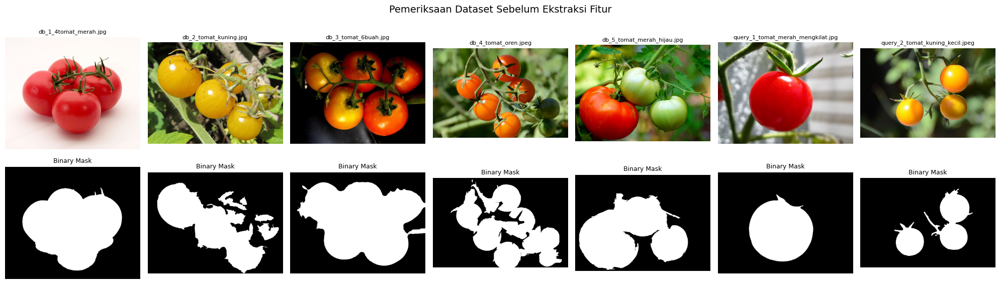

In [57]:
fig, ax = plt.subplots(2, 7, figsize=(20, 6))

for i, nama_file in enumerate(data_fitur):

    ax[0, i].imshow(citra_fitur[nama_file])
    ax[0, i].set_title(nama_file, fontsize=8)
    ax[0, i].axis("off")

    ax[1, i].imshow(
        mask_fitur[nama_file],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax[1, i].set_title("Binary Mask", fontsize=9)
    ax[1, i].axis("off")

plt.suptitle(
    "Pemeriksaan Dataset Sebelum Ekstraksi Fitur",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 3.1 - Ekstraksi Fitur Warna





### A. Ekstraksi Fitur Warna

| Kelompok | Fitur | Jumlah |
|---|---|---:|
| Warna | Mean RGB (R, G, B) | 3 |
| Warna | Standard Deviation RGB | 3 |
| Warna | Histogram Hue HSV (9 bin) | 9 |

----
Fitur warna dipilih karena citra tomat memiliki variasi warna yang berkaitan dengan tingkat kematangan, mulai dari hijau, kuning, oranye, hingga merah.

Ketiga fitur tersebut memiliki fungsi yang saling melengkapi:
1. **Mean RGB:** Menggambarkan nilai rata-rata warna merah, hijau, dan biru pada objek tomat.
2. **Standard Deviation RGB:** Mengukur tingkat variasi atau penyebaran intensitas warna pada objek tomat.
3. **Histogram Hue HSV:** Menggambarkan distribusi warna berdasarkan komponen Hue sehingga karakteristik warna objek dapat dianalisis secara lebih detail.


In [58]:
def ekstraksi_warna(img, mask):
    piksel_objek = img[mask > 0]
    mean_rgb = np.mean(piksel_objek, axis=0)
    std_rgb = np.std(piksel_objek, axis=0)

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    piksel_hsv = hsv[mask > 0]

    piksel_berwarna = piksel_hsv[piksel_hsv[:, 1] > 30]

    if len(piksel_berwarna) > 0:
        hue = piksel_berwarna[:, 0].astype(np.int16)
        hue = (hue + 10) % 180

        histogram, _ = np.histogram(
            hue,
            bins=9,
            range=(0, 180)
        )

        histogram = histogram.astype(float)
        histogram = histogram / histogram.sum()

    else:
        histogram = np.zeros(9)

    fitur = {
        "mean_R": mean_rgb[0],
        "mean_G": mean_rgb[1],
        "mean_B": mean_rgb[2],

        "std_R": std_rgb[0],
        "std_G": std_rgb[1],
        "std_B": std_rgb[2]
    }

    for i in range(9):
        fitur[f"hist_H_{i+1}"] = histogram[i]

    return fitur

print("Fungsi ekstraksi fitur warna berhasil dibuat")

Fungsi ekstraksi fitur warna berhasil dibuat


In [59]:
# MENGHITUNG FITUR WARNA 7 CITRA TOMAT

hasil_warna = []

for nama_file in data_fitur:

    img = citra_fitur[nama_file]
    mask = mask_fitur[nama_file]

    fitur = ekstraksi_warna(img, mask)

    hasil_warna.append({
        "nama_file": nama_file,
        **fitur
    })

# Membuat tabel hasil ekstraksi
df_warna = pd.DataFrame(hasil_warna)

print("Jumlah citra :", len(df_warna))
print("Jumlah fitur :", len(df_warna.columns) - 1)

# Menampilkan fitur Mean dan Standard Deviation
display(
    df_warna[
        [
            "nama_file",
            "mean_R", "mean_G", "mean_B",
            "std_R", "std_G", "std_B"
        ]
    ].round(3)
)

Jumlah citra : 7
Jumlah fitur : 15


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B
0,db_1_4tomat_merah.jpg,190.602,63.176,58.716,45.593,42.871,40.174
1,db_2_tomat_kuning.jpg,201.263,158.893,24.809,39.167,36.735,42.009
2,db_3_tomat_6buah.jpg,135.116,59.885,7.167,77.815,51.905,14.974
3,db_4_tomat_oren.jpeg,146.230,93.346,31.006,75.735,49.350,43.410
4,db_5_tomat_merah_hijau.jpg,157.402,106.237,47.215,69.008,80.027,66.914
5,query_1_tomat_merah_mengkilat.jpg,189.103,19.083,19.012,40.238,40.484,38.279
6,query_2_tomat_kuning_kecil.jpeg,211.144,149.152,24.373,52.636,49.975,38.617


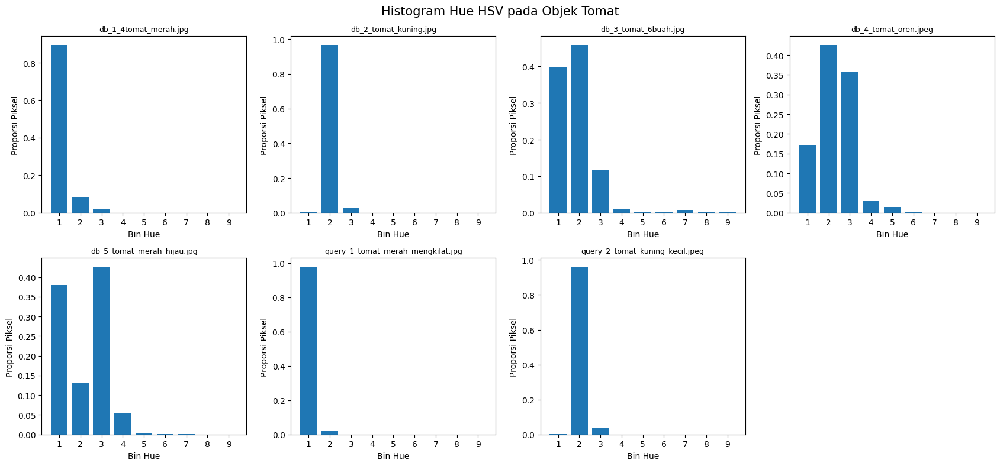

In [60]:
# VISUALISASI HISTOGRAM HUE 7 CITRA TOMAT

fig, ax = plt.subplots(2, 4, figsize=(17, 8))

kolom_hist = [
    f"hist_H_{i+1}" for i in range(9)
]

for i, nama_file in enumerate(data_fitur):

    baris = i // 4
    kolom = i % 4

    nilai_hist = df_warna.loc[
        df_warna["nama_file"] == nama_file,
        kolom_hist
    ].iloc[0].to_numpy(dtype=float)

    ax[baris, kolom].bar(
        range(1, 10),
        nilai_hist
    )

    ax[baris, kolom].set_title(
        nama_file, fontsize=9
    )

    ax[baris, kolom].set_xlabel("Bin Hue")
    ax[baris, kolom].set_ylabel("Proporsi Piksel")
    ax[baris, kolom].set_xticks(range(1, 10))

ax[1, 3].axis("off")

plt.suptitle(
    "Histogram Hue HSV pada Objek Tomat",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Interpretasi Histogram

| Gambar | Pola Histogram | Interpretasi |
|---|---|---|
| DB 1 | Bin 1 sangat dominan | Tomat merah |
| DB 2 | Bin 2 sangat dominan | Tomat kuning |
| DB 3 | Bin 1 dan 2 | Kombinasi merah dan oranye |
| DB 4 | Bin 1, 2, dan 3 | Warna lebih beragam |
| DB 5 | Bin 1 dan 3 dominan | Tomat merah dan hijau |
| Query 1 | Bin 1 sangat dominan | Tomat merah |
| Query 2 | Bin 2 sangat dominan | Tomat kuning |


## 3.2 - Ekstraksi Fitur Bentuk

#### Apa yang akan kita hitung?

| Fitur | Fungsi |
|---|---|
| Area Ratio | Mengukur proporsi luas objek tomat terhadap keseluruhan gambar |
| Aspect Ratio | Mengukur perbandingan lebar dan tinggi objek |
| Circularity | Mengukur seberapa mendekati bentuk lingkaran |

Dataset citra tomat memiliki variasi jumlah, ukuran, dan susunan objek, mulai dari tomat tunggal hingga tomat yang bergerombol.

Ketiga fitur tersebut memiliki fungsi yang saling melengkapi:

1. **Area Ratio:** Mengukur proporsi luas objek tomat terhadap keseluruhan citra.
2. **Aspect Ratio:** Mengukur perbandingan lebar dan tinggi objek berdasarkan bounding box.
3. **Circularity:** Mengukur tingkat kebulatan objek tomat berdasarkan luas dan kelilingnya.

Dengan menggabungkan ketiga fitur tersebut, sistem CBIR diharapkan dapat membedakan citra tomat berdasarkan karakteristik bentuknya.


A. Area Ratio

$$
\text{Area Ratio} = \frac{\text{Jumlah piksel objek}}{\text{Total piksel gambar}}
$$

B. Aspect Ratio

$$
\text{Aspect Ratio} = \frac{\text{Lebar Bounding Box}}{\text{Tinggi Bounding Box}}
$$

C. Circularity

$$
C = \frac{4\pi A}{P^2}
$$

Keterangan:
- **A** = Luas objek tomat
- **P** = Keliling objek tomat
- **C** = Nilai circularity


In [61]:
# 3.2 - EKSTRAKSI FITUR BENTUK

def ekstraksi_bentuk(mask):

    # 1. Memastikan mask berbentuk binary (0 dan 255)
    binary = np.where(
        mask > 0, 255, 0
    ).astype(np.uint8)

    tinggi, lebar = binary.shape

    # 2. Menghitung luas objek berdasarkan piksel putih
    area_px = np.count_nonzero(binary)

    # 3. Menghitung Area Ratio
    total_piksel = tinggi * lebar
    area_ratio = area_px / total_piksel

    # 4. Mengambil koordinat objek
    titik_objek = cv2.findNonZero(binary)

    # Menghitung Bounding Box gabungan seluruh objek
    x, y, bbox_w, bbox_h = cv2.boundingRect(
        titik_objek
    )

    # 5. Menghitung Aspect Ratio
    aspect_ratio = bbox_w / bbox_h

    # 6. Mencari seluruh kontur eksternal objek
    kontur, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # 7. Menghitung luas dan keliling kontur
    area_kontur = sum(
        cv2.contourArea(k)
        for k in kontur
    )

    perimeter = sum(
        cv2.arcLength(k, True)
        for k in kontur
    )

    # 8. Menghitung Circularity
    if perimeter > 0:
        circularity = (4 * np.pi * area_kontur) / (perimeter ** 2)
    else:
        circularity = 0

    # 9. Menyimpan ketiga fitur utama
    fitur = {
        "area_ratio": area_ratio,
        "aspect_ratio": aspect_ratio,
        "circularity": circularity
    }

    informasi = {
        "area_px": area_px,
        "perimeter_px": perimeter,
        "bbox_width": bbox_w,
        "bbox_height": bbox_h
    }

    return fitur, informasi


print("Fungsi ekstraksi fitur bentuk berhasil dibuat!")

Fungsi ekstraksi fitur bentuk berhasil dibuat!


In [62]:
# MENGHITUNG FITUR BENTUK 7 CITRA TOMAT

hasil_bentuk = []

for nama_file in data_fitur:
    mask = mask_fitur[nama_file]

    fitur, informasi = ekstraksi_bentuk(mask)

    hasil_bentuk.append({
        "nama_file": nama_file,
        **fitur,
        **informasi
    })

df_bentuk = pd.DataFrame(hasil_bentuk)

print("Jumlah citra :", len(df_bentuk))
print("Jumlah fitur : 3")

display(
    df_bentuk[
        [
            "nama_file",
            "area_ratio",
            "aspect_ratio",
            "circularity",
            "area_px",
            "perimeter_px"
        ]
    ].round(4)
)

Jumlah citra : 7
Jumlah fitur : 3


,nama_file,area_ratio,aspect_ratio,circularity,area_px,perimeter_px
0,db_1_4tomat_merah.jpg,0.3677,1.2024,0.6255,281659,2374.4663
1,db_2_tomat_kuning.jpg,0.3355,1.3494,0.0892,231904,5686.2362
2,db_3_tomat_6buah.jpg,0.5225,1.5320,0.3834,361123,3433.5659
3,db_4_tomat_oren.jpeg,0.3686,1.2604,0.0883,225064,5779.0818
4,db_5_tomat_merah_hijau.jpg,0.3958,1.4280,0.2094,259903,3936.3670
5,query_1_tomat_merah_mengkilat.jpg,0.2259,0.9580,0.7536,156142,1610.0012
6,query_2_tomat_kuning_kecil.jpeg,0.1685,1.1653,0.1454,102878,2963.1912


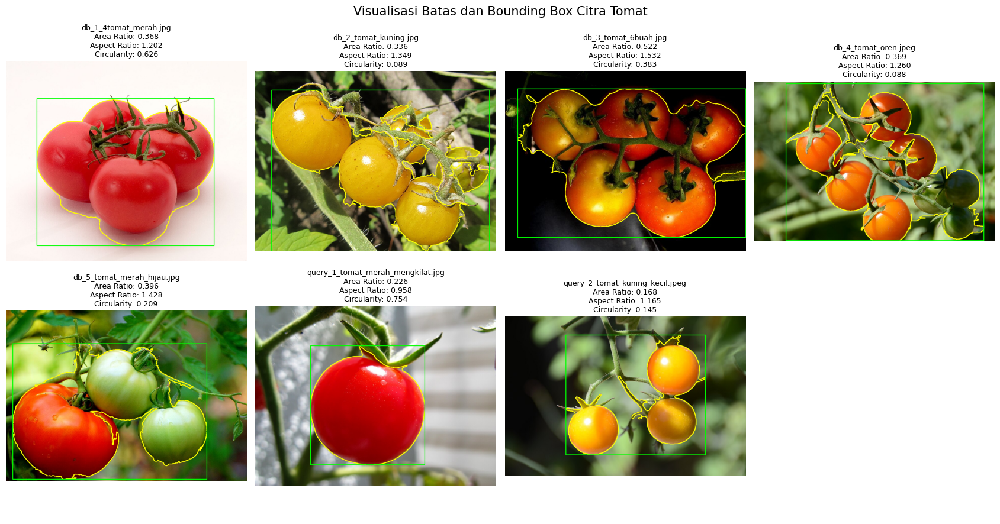

Kuning = Batas objek
Hijau  = Bounding Box objek


In [63]:
# VISUALISASI FITUR BENTUK 7 CITRA TOMAT

fig, ax = plt.subplots(2, 4, figsize=(17, 9))

for i, nama_file in enumerate(data_fitur):
    img = citra_fitur[nama_file].copy()
    mask = mask_fitur[nama_file]

    kontur, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        img,
        kontur,
        -1,
        (255, 255, 0),
        2
    )

    x, y, w, h = cv2.boundingRect(
        cv2.findNonZero(mask)
    )

    cv2.rectangle(
        img,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 255, 0),
        2
    )

    baris = df_bentuk.loc[
        df_bentuk["nama_file"] == nama_file
    ].iloc[0]

    a = ax.flat[i]

    a.imshow(img)
    a.set_title(
        f"{nama_file}\n"
        f"Area Ratio: {baris['area_ratio']:.3f}\n"
        f"Aspect Ratio: {baris['aspect_ratio']:.3f}\n"
        f"Circularity: {baris['circularity']:.3f}",
        fontsize=9
    )
    a.axis("off")

ax.flat[-1].axis("off")

plt.suptitle(
    "Visualisasi Batas dan Bounding Box Citra Tomat",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("Kuning = Batas objek")
print("Hijau  = Bounding Box objek")

### Interpretasi Hasil Ekstraksi Fitur Bentuk

- **Area Ratio:** DB 3 memiliki nilai tertinggi (0,522), menunjukkan bahwa objek menempati sekitar 52,2% luas citra. Sementara itu, Query 2 memiliki nilai terendah (0,168).
- **Aspect Ratio:** Seluruh citra memiliki nilai yang bervariasi. Query 1 memiliki nilai 0,958 yang menunjukkan bentuk objek hampir seimbang antara lebar dan tinggi, sedangkan DB 3 memiliki nilai 1,532 yang menunjukkan objek lebih melebar secara horizontal.
- **Circularity:** Query 1 memiliki nilai tertinggi (0,754), menunjukkan bentuk objek paling mendekati lingkaran. Sebaliknya, DB 2 (0,089) dan DB 4 (0,088) memiliki nilai rendah karena kontur objek lebih kompleks dan tidak beraturan.

Secara keseluruhan, fitur bentuk mampu merepresentasikan perbedaan karakteristik geometris antar citra tomat. Namun, hasilnya dipengaruhi oleh jumlah objek, keberadaan tangkai, serta kualitas segmentasi, terutama pada DB 2 dan DB 4 yang masih mengandung sebagian background.

## 3.3 - Ekstraksi Fitur Tekstur (GLCM)

GLCM (Gray-Level Co-occurrence Matrix) adalah metode ekstraksi fitur tekstur yang menghitung seberapa sering pasangan intensitas piksel muncul berdekatan dalam sebuah citra. Kita ingin mengetahui bagaimana pola permukaan tomat berdasarkan perubahan intensitas antar-piksel.


### Tiga Fitur Tekstur yang Digunakan

| Fitur | Artinya |
|---|---|
| Contrast | Mengukur besarnya perbedaan intensitas piksel yang berdekatan. Semakin tinggi, semakin besar variasi lokalnya. |
| Homogeneity | Mengukur keseragaman intensitas piksel bertetangga. Semakin tinggi, semakin seragam. |
| Energy | Mengukur konsentrasi distribusi pasangan intensitas. Semakin tinggi, semakin teratur atau terkonsentrasi polanya. |


Fitur tekstur dipilih karena setiap citra tomat memiliki pola distribusi intensitas piksel yang berbeda, yang tidak sepenuhnya dapat direpresentasikan hanya melalui fitur warna dan bentuk.

1. **Contrast:** Mengukur tingkat perbedaan intensitas antar-piksel yang berdekatan untuk mengetahui variasi tekstur lokal.
2. **Homogeneity:** Mengukur tingkat keseragaman intensitas antar-piksel. Semakin tinggi nilainya, semakin seragam intensitas piksel yang bertetangga.
3. **Energy:** Mengukur tingkat konsentrasi distribusi pasangan intensitas piksel untuk menggambarkan keteraturan pola tekstur.

Dengan menggabungkan fitur tekstur bersama fitur warna dan bentuk, sistem CBIR diharapkan dapat membandingkan citra tomat berdasarkan karakteristik visual yang lebih lengkap sehingga hasil pencarian citra menjadi lebih representatif.


In [64]:
# 3.3 - EKSTRAKSI FITUR TEKSTUR GLCM

def ekstraksi_tekstur(img, mask):

    # Menyamakan skala ukuran citra
    tinggi, lebar = img.shape[:2]

    skala = 384 / max(tinggi, lebar)

    ukuran_baru = (
        max(1, round(lebar * skala)),
        max(1, round(tinggi * skala))
    )

    img_resize = cv2.resize(
        img,
        ukuran_baru,
        interpolation=cv2.INTER_AREA if skala < 1 else cv2.INTER_LINEAR
    )

    mask_resize = cv2.resize(
        mask,
        ukuran_baru,
        interpolation=cv2.INTER_NEAREST
    )

    gray = cv2.cvtColor(
        img_resize,
        cv2.COLOR_RGB2GRAY
    )

    # Kuantisasi grayscale dari 256 menjadi 16 level
    levels = 16
    gray = (gray // 16).astype(np.uint8)

    objek = mask_resize > 0

    # Empat arah GLCM dengan jarak 1 piksel
    arah = [
        (0, 1),     # 0 derajat
        (-1, 1),    # 45 derajat
        (-1, 0),    # 90 derajat
        (-1, -1)    # 135 derajat
    ]

    indeks = np.arange(levels)
    selisih = indeks[:, None] - indeks[None, :]

    hasil_arah = []
    matriks_glcm = []

    for dy, dx in arah:
        y0 = max(0, -dy)
        y1 = min(gray.shape[0], gray.shape[0] - dy)

        x0 = max(0, -dx)
        x1 = min(gray.shape[1], gray.shape[1] - dx)

        piksel_1 = gray[y0:y1, x0:x1]
        piksel_2 = gray[
            y0+dy:y1+dy,
            x0+dx:x1+dx
        ]

        mask_1 = objek[y0:y1, x0:x1]
        mask_2 = objek[
            y0+dy:y1+dy,
            x0+dx:x1+dx
        ]

        valid = mask_1 & mask_2

        if not np.any(valid):
            continue

        kode = (
            piksel_1[valid].astype(np.int32) * levels
            + piksel_2[valid].astype(np.int32)
        )

        glcm = np.bincount(
            kode,
            minlength=levels * levels
        ).reshape(levels, levels).astype(np.float64)

        glcm = glcm + glcm.T
        glcm = glcm / glcm.sum()
        matriks_glcm.append(glcm)

        contrast = np.sum(
            glcm * (selisih ** 2)
        )

        homogeneity = np.sum(
            glcm / (1 + selisih ** 2)
        )

        energy = np.sqrt(
            np.sum(glcm ** 2)
        )

        hasil_arah.append([
            contrast,
            homogeneity,
            energy
        ])

    rata_rata = np.mean(hasil_arah, axis=0)

    fitur = {
        "glcm_contrast": rata_rata[0],
        "glcm_homogeneity": rata_rata[1],
        "glcm_energy": rata_rata[2]
    }

    glcm_rata = np.mean(matriks_glcm, axis=0)

    return fitur, glcm_rata

print("Fungsi ekstraksi fitur tekstur berhasil dibuat!")

Fungsi ekstraksi fitur tekstur berhasil dibuat!


In [65]:
# MENGHITUNG FITUR TEKSTUR 7 CITRA TOMAT

hasil_tekstur = []

glcm_matrices = {}

for nama_file in data_fitur:

    img = citra_fitur[nama_file]
    mask = mask_fitur[nama_file]

    fitur, matriks = ekstraksi_tekstur(img, mask)

    hasil_tekstur.append({
        "nama_file": nama_file,
        **fitur
    })

df_tekstur = pd.DataFrame(hasil_tekstur)

print("Jumlah citra :", len(df_tekstur))
print("Jumlah fitur :", len(df_tekstur.columns) - 1)

display(df_tekstur.round(4))

Jumlah citra : 7
Jumlah fitur : 3


,nama_file,glcm_contrast,glcm_homogeneity,glcm_energy
0,db_1_4tomat_merah.jpg,0.7242,0.8325,0.2674
1,db_2_tomat_kuning.jpg,0.8935,0.8199,0.3042
2,db_3_tomat_6buah.jpg,0.5971,0.8285,0.2206
3,db_4_tomat_oren.jpeg,1.2550,0.7914,0.2144
4,db_5_tomat_merah_hijau.jpg,0.6508,0.8539,0.2087
5,query_1_tomat_merah_mengkilat.jpg,0.2743,0.9180,0.4378
6,query_2_tomat_kuning_kecil.jpeg,0.5326,0.8663,0.2516


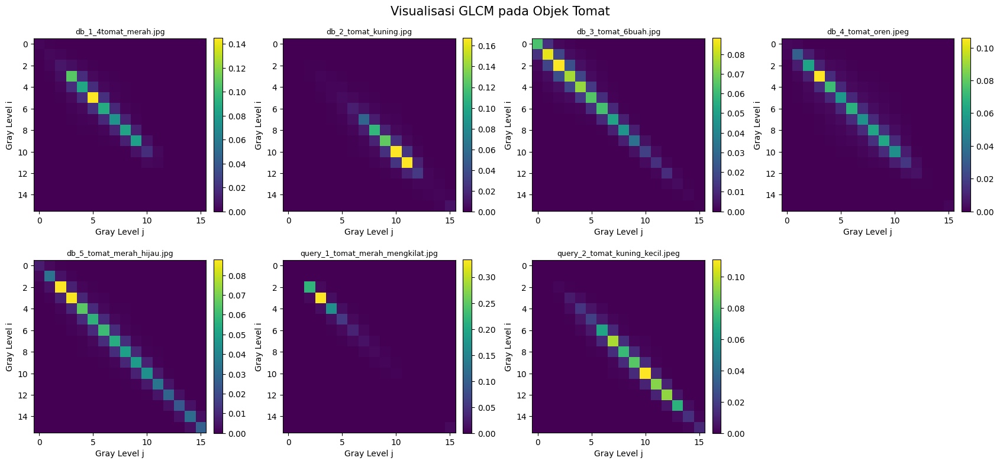

In [66]:
# VISUALISASI MATRIKS GLCM 7 CITRA TOMAT

fig, ax = plt.subplots(2, 4, figsize=(17, 8))

for i, nama_file in enumerate(data_fitur):
    img = citra_fitur[nama_file]
    mask = mask_fitur[nama_file]

    fitur, glcm = ekstraksi_tekstur(img, mask)

    baris = i // 4
    kolom = i % 4

    im = ax[baris, kolom].imshow(
        glcm,
        cmap="viridis",
        interpolation="nearest"
    )

    ax[baris, kolom].set_title(nama_file, fontsize=9)
    ax[baris, kolom].set_xlabel("Gray Level j")
    ax[baris, kolom].set_ylabel("Gray Level i")

    plt.colorbar(
        im,
        ax=ax[baris, kolom],
        fraction=0.046,
        pad=0.04
    )

ax[1, 3].axis("off")

plt.suptitle(
    "Visualisasi GLCM pada Objek Tomat",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi GLCM

Berdasarkan hasil visualisasi GLCM, sebagian besar citra tomat memiliki pola warna terang yang terkonsentrasi di sekitar garis diagonal. Hal ini menunjukkan bahwa piksel-piksel yang berdekatan cenderung memiliki tingkat keabuan yang hampir sama, sehingga tekstur citra relatif seragam.

1. **DB 1 (Tomat Merah):** Pola GLCM terkonsentrasi pada bagian tengah diagonal. Hal ini menunjukkan bahwa intensitas piksel pada citra relatif seragam dengan variasi intensitas yang tidak terlalu besar.

2. **DB 2 (Tomat Kuning):** Pola GLCM lebih terkonsentrasi pada bagian kanan bawah diagonal. Artinya, pasangan piksel dengan tingkat keabuan lebih tinggi lebih sering muncul dibandingkan citra lainnya.

3. **DB 3 (Tomat 6 Buah):** Pola GLCM tersebar cukup panjang di sepanjang diagonal. Hal ini menunjukkan bahwa citra memiliki variasi tingkat keabuan yang lebih beragam, tetapi piksel yang berdekatan masih cenderung memiliki intensitas yang mirip.

4. **DB 4 (Tomat Oranye):** Pola GLCM terlihat di sekitar diagonal dengan beberapa titik yang lebih terang. Hal ini menunjukkan adanya beberapa tingkat keabuan yang dominan, dengan tekstur yang relatif seragam.

5. **DB 5 (Tomat Merah Hijau):** Pola GLCM menyebar hampir di sepanjang diagonal. Hal ini menunjukkan bahwa citra memiliki rentang intensitas yang cukup beragam, tetapi hubungan antar-piksel masih didominasi oleh intensitas yang berdekatan.

6. **Query 1 (Tomat Merah Mengkilap):** Pola GLCM sangat terkonsentrasi pada beberapa titik di bagian kiri atas diagonal. Hal ini menunjukkan bahwa sebagian besar pasangan piksel memiliki tingkat keabuan rendah yang mirip, dengan distribusi intensitas yang lebih terkonsentrasi.

7. **Query 2 (Tomat Kuning Kecil):** Pola GLCM tersebar di sepanjang diagonal, terutama pada bagian tengah hingga kanan bawah. Hal ini menunjukkan adanya variasi tingkat keabuan, tetapi intensitas piksel yang bertetangga masih cenderung serupa.

### Kesimpulan

Secara keseluruhan, seluruh citra menunjukkan pola GLCM yang dominan di sekitar diagonal. Artinya, sebagian besar piksel yang bertetangga memiliki intensitas yang mirip. Perbedaan posisi dan penyebaran pola GLCM menunjukkan bahwa setiap citra memiliki karakteristik distribusi intensitas yang berbeda.



# 4. Membangun Database Fitur Global

In [67]:
# 4.1 - MENGGABUNGKAN FITUR GLOBAL

# fitur warna dan bentuk
df_fitur = pd.merge(
    df_warna,
    df_bentuk[
        ["nama_file", "area_ratio",
         "aspect_ratio", "circularity"]
    ],
    on="nama_file",
    validate="one_to_one"
)

# fitur tekstur
df_fitur = pd.merge(
    df_fitur,
    df_tekstur,
    on="nama_file",
    validate="one_to_one"
)

# Menentukan 21 kolom fitur
kolom_fitur = [
    kolom for kolom in df_fitur.columns
    if kolom != "nama_file"
]

# Validasi hasil
assert len(df_fitur) == 7, "Jumlah citra tidak sesuai"
assert len(kolom_fitur) == 21, "Jumlah fitur tidak sesuai"

assert np.isfinite(
    df_fitur[kolom_fitur].to_numpy(dtype=float)
).all(), "Terdapat nilai NaN atau Infinity"

print("Jumlah citra :", len(df_fitur))
print("Jumlah fitur :", len(kolom_fitur))
print("Ukuran tabel :", df_fitur.shape)

display(df_fitur.round(4))

Jumlah citra : 7
Jumlah fitur : 21
Ukuran tabel : (7, 22)


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,db_1_4tomat_merah.jpg,190.6023,63.1764,58.7162,45.5935,42.8708,40.1744,0.8963,0.0847,0.0183,...,0.0000,0.0003,0.0001,0.0000,0.3677,1.2024,0.6255,0.7242,0.8325,0.2674
1,db_2_tomat_kuning.jpg,201.2629,158.8934,24.8091,39.1670,36.7353,42.0089,0.0028,0.9679,0.0290,...,0.0000,0.0001,0.0000,0.0001,0.3355,1.3494,0.0892,0.8935,0.8199,0.3042
2,db_3_tomat_6buah.jpg,135.1161,59.8846,7.1674,77.8155,51.9052,14.9743,0.3967,0.4597,0.1164,...,0.0014,0.0083,0.0025,0.0023,0.5225,1.5320,0.3834,0.5971,0.8285,0.2206
3,db_4_tomat_oren.jpeg,146.2303,93.3465,31.0063,75.7354,49.3502,43.4097,0.1700,0.4264,0.3565,...,0.0024,0.0001,0.0000,0.0000,0.3686,1.2604,0.0883,1.2550,0.7914,0.2144
4,db_5_tomat_merah_hijau.jpg,157.4016,106.2375,47.2152,69.0084,80.0269,66.9142,0.3797,0.1320,0.4274,...,0.0003,0.0006,0.0002,0.0003,0.3958,1.4280,0.2094,0.6508,0.8539,0.2087
5,query_1_tomat_merah_mengkilat.jpg,189.1033,19.0830,19.0123,40.2382,40.4844,38.2794,0.9805,0.0192,0.0000,...,0.0000,0.0000,0.0000,0.0002,0.2259,0.9580,0.7536,0.2743,0.9180,0.4378
6,query_2_tomat_kuning_kecil.jpeg,211.1436,149.1517,24.3728,52.6365,49.9751,38.6166,0.0021,0.9622,0.0356,...,0.0000,0.0000,0.0000,0.0000,0.1685,1.1653,0.1454,0.5326,0.8663,0.2516


In [68]:
# 4.2 - MEMISAHKAN DATABASE DAN QUERY

# Mengambil 5 citra database
df_database = (
    df_fitur.set_index("nama_file")
    .loc[database_files]
    .reset_index()
)

# Mengambil 2 citra query
df_query = (
    df_fitur.set_index("nama_file")
    .loc[query_files]
    .reset_index()
)

print("Jumlah database:", len(df_database))
display(df_database.round(4))

print("Jumlah query:", len(df_query))
display(df_query.round(4))

Jumlah database: 5


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,db_1_4tomat_merah.jpg,190.6023,63.1764,58.7162,45.5935,42.8708,40.1744,0.8963,0.0847,0.0183,...,0.0000,0.0003,0.0001,0.0000,0.3677,1.2024,0.6255,0.7242,0.8325,0.2674
1,db_2_tomat_kuning.jpg,201.2629,158.8934,24.8091,39.1670,36.7353,42.0089,0.0028,0.9679,0.0290,...,0.0000,0.0001,0.0000,0.0001,0.3355,1.3494,0.0892,0.8935,0.8199,0.3042
2,db_3_tomat_6buah.jpg,135.1161,59.8846,7.1674,77.8155,51.9052,14.9743,0.3967,0.4597,0.1164,...,0.0014,0.0083,0.0025,0.0023,0.5225,1.5320,0.3834,0.5971,0.8285,0.2206
3,db_4_tomat_oren.jpeg,146.2303,93.3465,31.0063,75.7354,49.3502,43.4097,0.1700,0.4264,0.3565,...,0.0024,0.0001,0.0000,0.0000,0.3686,1.2604,0.0883,1.2550,0.7914,0.2144
4,db_5_tomat_merah_hijau.jpg,157.4016,106.2375,47.2152,69.0084,80.0269,66.9142,0.3797,0.1320,0.4274,...,0.0003,0.0006,0.0002,0.0003,0.3958,1.4280,0.2094,0.6508,0.8539,0.2087


Jumlah query: 2


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,query_1_tomat_merah_mengkilat.jpg,189.1033,19.0830,19.0123,40.2382,40.4844,38.2794,0.9805,0.0192,0.0000,...,0.0,0.0,0.0,0.0002,0.2259,0.9580,0.7536,0.2743,0.9180,0.4378
1,query_2_tomat_kuning_kecil.jpeg,211.1436,149.1517,24.3728,52.6365,49.9751,38.6166,0.0021,0.9622,0.0356,...,0.0,0.0,0.0,0.0000,0.1685,1.1653,0.1454,0.5326,0.8663,0.2516


In [69]:
# 4.3 - MENYIMPAN DATABASE FITUR GLOBAL

path_database = os.path.join(
    dataset_path,
    "database_fitur_global.csv"
)

path_query = os.path.join(
    dataset_path,
    "query_fitur_global.csv"
)

# Menyimpan tabel ke CSV
df_database.to_csv(path_database, index=False)
df_query.to_csv(path_query, index=False)

print("Database:", path_database)
print("Query   :", path_query)

Database: /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/database_fitur_global.csv
Query   : /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/query_fitur_global.csv


# 5. Normalisasi dan Pembobotan Fitur

### Pembobotan Kelompok Fitur
Untuk eksperimen awal, kita bisa mencoba bobot kelompok:
| Fitur | Bobot |
|---|---:|
| Warna | 50% |
| Bentuk | 25% |
| Tekstur | 25% |

---

1. **Warna (50%):** Diberikan bobot terbesar karena warna merupakan salah satu karakteristik utama untuk membedakan citra tomat, seperti merah, kuning, oranye, dan hijau.
2. **Bentuk (25%):** Digunakan untuk mempertimbangkan perbedaan ukuran, proporsi, dan bentuk objek tomat.
3. **Tekstur (25%):** Digunakan untuk melengkapi informasi warna dan bentuk melalui karakteristik distribusi intensitas piksel.


In [70]:
# 5.1 - NORMALISASI FITUR MENGGUNAKAN MIN-MAX

X_database = df_database[kolom_fitur].copy()
X_query = df_query[kolom_fitur].copy()

nilai_min = X_database.min()
nilai_max = X_database.max()

rentang = nilai_max - nilai_min
fitur_konstan = rentang[rentang == 0].index.tolist()
rentang_aman = rentang.replace(0, 1)

# Normalisasi database
db_normal = (X_database - nilai_min) / rentang_aman
query_normal = (X_query - nilai_min) / rentang_aman

if fitur_konstan:
    db_normal[fitur_konstan] = 0.0
    query_normal[fitur_konstan] = 0.0

df_db_normal = db_normal.copy()
df_db_normal.insert(
    0, "nama_file", df_database["nama_file"]
)

df_query_normal = query_normal.copy()
df_query_normal.insert(
    0, "nama_file", df_query["nama_file"]
)

print("=== NORMALISASI MIN-MAX ===")
print("Database:", db_normal.shape)
print("Query   :", query_normal.shape)
print("Fitur konstan:", fitur_konstan)

print("\n=== DATABASE NORMAL ===")
display(df_db_normal.round(4))

print("\n=== QUERY NORMAL ===")
display(df_query_normal.round(4))

=== NORMALISASI MIN-MAX ===
Database: (5, 21)
Query   : (2, 21)
Fitur konstan: []

=== DATABASE NORMAL ===


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,db_1_4tomat_merah.jpg,0.8388,0.0332,1.0000,0.1663,0.1417,0.4852,1.0000,0.0000,0.0000,...,0.0045,0.0238,0.0253,0.0000,0.1720,0.0000,1.0000,0.1932,0.6578,0.6145
1,db_2_tomat_kuning.jpg,1.0000,1.0000,0.3422,0.0000,0.0000,0.5205,0.0000,1.0000,0.0261,...,0.0000,0.0000,0.0140,0.0324,0.0000,0.4460,0.0016,0.4505,0.4553,1.0000
2,db_3_tomat_6buah.jpg,0.0000,0.0000,0.0000,1.0000,0.3504,0.0000,0.4408,0.4246,0.2398,...,0.5762,1.0000,1.0000,1.0000,1.0000,1.0000,0.5493,0.0000,0.5939,0.1245
3,db_4_tomat_oren.jpeg,0.1680,0.3380,0.4625,0.9462,0.2914,0.5475,0.1871,0.3869,0.8268,...,1.0000,0.0007,0.0000,0.0020,0.1771,0.1760,0.0000,1.0000,0.0000,0.0595
4,db_5_tomat_merah_hijau.jpg,0.3369,0.4682,0.7769,0.7721,1.0000,1.0000,0.4219,0.0536,1.0000,...,0.1356,0.0617,0.0595,0.1103,0.3225,0.6846,0.2255,0.0815,1.0000,0.0000



=== QUERY NORMAL ===


,nama_file,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,query_1_tomat_merah_mengkilat.jpg,0.8162,-0.4121,0.2298,0.0277,0.0866,0.4487,1.0942,-0.0741,-0.0448,...,-0.0072,-0.0069,-0.0018,0.0758,-0.5863,-0.7415,1.2385,-0.4908,2.0251,2.3984
1,query_2_tomat_kuning_kecil.jpeg,1.1494,0.9016,0.3338,0.3485,0.3058,0.4552,-0.0007,0.9935,0.0422,...,-0.0072,-0.0069,-0.0018,-0.0157,-0.8934,-0.1126,0.1064,-0.0981,1.1991,0.4493


In [71]:
# 5.2 - PEMBOBOTAN KELOMPOK FITUR

fitur_warna = [
    "mean_R", "mean_G", "mean_B",
    "std_R", "std_G", "std_B"
] + [f"hist_H_{i+1}" for i in range(9)]

fitur_bentuk = [
    "area_ratio",
    "aspect_ratio",
    "circularity"
]

fitur_tekstur = [
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy"
]

# Bobot kelompok fitur
bobot_kelompok = {
    "Warna": 0.50,
    "Bentuk": 0.25,
    "Tekstur": 0.25
}

kelompok_fitur = {
    "Warna": fitur_warna,
    "Bentuk": fitur_bentuk,
    "Tekstur": fitur_tekstur
}

bobot_fitur = {}

for kelompok, daftar_fitur in kelompok_fitur.items():

    fitur_aktif = [
        f for f in daftar_fitur
        if f not in fitur_konstan
    ]

    if not fitur_aktif:
        continue

    bobot = np.sqrt(
        bobot_kelompok[kelompok] / len(fitur_aktif)
    )

    for fitur in fitur_aktif:
        bobot_fitur[fitur] = bobot

df_bobot = pd.DataFrame({
    "Fitur": kolom_fitur,
    "Bobot": [
        bobot_fitur.get(f, 0.0)
        for f in kolom_fitur
    ]
})

display(df_bobot.round(5))

print("Total kontribusi bobot kuadrat:",
      sum(b ** 2 for b in bobot_fitur.values()))

,Fitur,Bobot
0,mean_R,0.18257
1,mean_G,0.18257
2,mean_B,0.18257
3,std_R,0.18257
4,std_G,0.18257
5,std_B,0.18257
6,hist_H_1,0.18257
7,hist_H_2,0.18257
8,hist_H_3,0.18257
9,hist_H_4,0.18257


Total kontribusi bobot kuadrat: 1.0


In [72]:
# 5.3 - MENERAPKAN BOBOT PADA FITUR

db_weighted = db_normal.copy()
query_weighted = query_normal.copy()

for fitur in kolom_fitur:

    bobot = bobot_fitur.get(fitur, 0.0)

    db_weighted[fitur] *= bobot
    query_weighted[fitur] *= bobot

print("=== HASIL NORMALISASI + PEMBOBOTAN ===")

print("Database:", db_weighted.shape)
print("Query   :", query_weighted.shape)

print("\nFitur database setelah pembobotan:")
display(db_weighted.round(4))

print("\nFitur query setelah pembobotan:")
display(query_weighted.round(4))

assert np.isfinite(db_weighted.to_numpy()).all()
assert np.isfinite(query_weighted.to_numpy()).all()


=== HASIL NORMALISASI + PEMBOBOTAN ===
Database: (5, 21)
Query   : (2, 21)

Fitur database setelah pembobotan:


,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,hist_H_4,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,0.1531,0.0061,0.1826,0.0304,0.0259,0.0886,0.1826,0.0000,0.0000,0.0008,...,0.0008,0.0043,0.0046,0.0000,0.0496,0.0000,0.2887,0.0558,0.1899,0.1774
1,0.1826,0.1826,0.0625,0.0000,0.0000,0.0950,0.0000,0.1826,0.0048,0.0000,...,0.0000,0.0000,0.0025,0.0059,0.0000,0.1287,0.0005,0.1300,0.1314,0.2887
2,0.0000,0.0000,0.0000,0.1826,0.0640,0.0000,0.0805,0.0775,0.0438,0.0336,...,0.1052,0.1826,0.1826,0.1826,0.2887,0.2887,0.1586,0.0000,0.1714,0.0360
3,0.0307,0.0617,0.0844,0.1727,0.0532,0.1000,0.0342,0.0706,0.1510,0.0969,...,0.1826,0.0001,0.0000,0.0004,0.0511,0.0508,0.0000,0.2887,0.0000,0.0172
4,0.0615,0.0855,0.1418,0.1410,0.1826,0.1826,0.0770,0.0098,0.1826,0.1826,...,0.0248,0.0113,0.0109,0.0201,0.0931,0.1976,0.0651,0.0235,0.2887,0.0000



Fitur query setelah pembobotan:


,mean_R,mean_G,mean_B,std_R,std_G,std_B,hist_H_1,hist_H_2,hist_H_3,hist_H_4,...,hist_H_6,hist_H_7,hist_H_8,hist_H_9,area_ratio,aspect_ratio,circularity,glcm_contrast,glcm_homogeneity,glcm_energy
0,0.1490,-0.0752,0.0420,0.0051,0.0158,0.0819,0.1998,-0.0135,-0.0082,-0.0000,...,-0.0013,-0.0013,-0.0003,0.0138,-0.1693,-0.2140,0.3575,-0.1417,0.5846,0.6924
1,0.2098,0.1646,0.0609,0.0636,0.0558,0.0831,-0.0001,0.1814,0.0077,0.0002,...,-0.0013,-0.0013,-0.0003,-0.0029,-0.2579,-0.0325,0.0307,-0.0283,0.3462,0.1297


# 6. Pencarian CBIR - Menggunakan Euclidean Distance

In [73]:
# 6.1 - MENGHITUNG WEIGHTED EUCLIDEAN DISTANCE

hasil_pencarian = []

fitur_db = db_weighted.to_numpy(dtype=float)
fitur_query = query_weighted.to_numpy(dtype=float)

for i, nama_query in enumerate(df_query["nama_file"]):
    vektor_query = fitur_query[i]

    jarak = np.linalg.norm(
        fitur_db - vektor_query,
        axis=1
    )

    urutan = np.argsort(jarak)

    for peringkat, indeks_db in enumerate(urutan, start=1):
        hasil_pencarian.append({
            "query": nama_query,
            "ranking": peringkat,
            "database": df_database.iloc[indeks_db]["nama_file"],
            "distance": jarak[indeks_db]
        })

df_ranking = pd.DataFrame(hasil_pencarian)

print("=== HASIL PENCARIAN CBIR ===")
print("Metode: Weighted Euclidean Distance")

for nama_query in df_query["nama_file"]:

    print(f"\nQuery: {nama_query}")

    hasil = df_ranking[
        df_ranking["query"] == nama_query
    ]

    display(
        hasil[["ranking", "database", "distance"]]
        .round(4)
        .reset_index(drop=True)
    )

=== HASIL PENCARIAN CBIR ===
Metode: Weighted Euclidean Distance

Query: query_1_tomat_merah_mengkilat.jpg


,ranking,database,distance
0,1,db_1_4tomat_merah.jpg,0.7658
1,2,db_2_tomat_kuning.jpg,0.9289
2,3,db_5_tomat_merah_hijau.jpg,1.0521
3,4,db_3_tomat_6buah.jpg,1.1525
4,5,db_4_tomat_oren.jpeg,1.1960



Query: query_2_tomat_kuning_kecil.jpeg


,ranking,database,distance
0,1,db_2_tomat_kuning.jpg,0.4454
1,2,db_1_4tomat_merah.jpg,0.5546
2,3,db_5_tomat_merah_hijau.jpg,0.6086
3,4,db_4_tomat_oren.jpeg,0.7087
4,5,db_3_tomat_6buah.jpg,0.8295


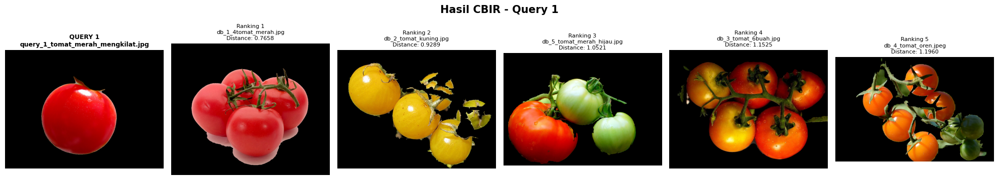

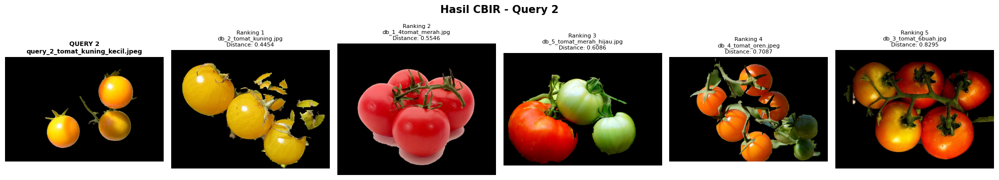

In [74]:
# 6.2 - VISUALISASI RANKING HASIL CBIR

def tampilkan_objek(nama_file):

    img = citra_fitur[nama_file]
    mask = mask_fitur[nama_file]

    return cv2.bitwise_and(
        img, img, mask=mask
    )


for i, nama_query in enumerate(df_query["nama_file"]):

    # Mengambil 5 hasil ranking
    hasil = df_ranking[
        df_ranking["query"] == nama_query
    ].sort_values("ranking")

    # 1 query + 5 database
    fig, ax = plt.subplots(1, 6, figsize=(20, 4))

    # Menampilkan query
    ax[0].imshow(tampilkan_objek(nama_query))
    ax[0].set_title(
        f"QUERY {i+1}\n{nama_query}",
        fontsize=9,
        fontweight="bold"
    )
    ax[0].axis("off")

    # Menampilkan 5 database sesuai ranking
    for j, (_, baris) in enumerate(hasil.iterrows(), start=1):

        nama_db = baris["database"]
        distance = baris["distance"]

        ax[j].imshow(tampilkan_objek(nama_db))

        ax[j].set_title(
            f"Ranking {j}\n"
            f"{nama_db}\n"
            f"Distance: {distance:.4f}",
            fontsize=8
        )

        ax[j].axis("off")

    plt.suptitle(
        f"Hasil CBIR - Query {i+1}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

In [75]:
# 6.3 - MENYIMPAN HASIL RANKING CBIR

path_ranking = os.path.join(
    dataset_path,
    "hasil_ranking_cbir.csv"
)

df_ranking.to_csv(
    path_ranking,
    index=False
)

print("=== HASIL RANKING CBIR TERSIMPAN ===")
print("Lokasi:", path_ranking)

print("\nTotal query:", df_ranking["query"].nunique())
print("Total perbandingan:", len(df_ranking))


=== HASIL RANKING CBIR TERSIMPAN ===
Lokasi: /content/drive/MyDrive/SEMESTER 5/Computer Vision/Dataset/hasil_ranking_cbir.csv

Total query: 2
Total perbandingan: 10


# 7. Analisis Hasil CBIR

### A. Mengapa citra peringkat pertama paling mirip menurut fitur yang digunakan?

- Query 1 memiliki kemiripan tertinggi dengan DB 1, dengan jarak sebesar **0,7658**. Keduanya memiliki warna merah yang dominan, dengan proporsi histogram Hue pada Bin 1 sebesar 0,9805 (Query 1) dan 0,8963 (DB 1). Dan juga keduanya memiliki bentuk yg ngebulat.

- Query 2 memiliki kemiripan tertinggi dengan DB 2, dengan jarak sebesar **0,4454**. Keduanya memiliki karakteristik warna kuning yang serupa, ditunjukkan  histogram Hue pada Bin 2 sebesar 0,9622 (Query 2) dan 0,9679 (DB 2).

Kedua gambar tersebut memperoleh peringkat pertama karena memiliki jarak gabungan fitur ternormalisasi dan terbobot yang paling kecil.

### B. Apakah hasil pencarian sesuai dengan pengamatan visual?

Secara umum **hasil peringkat pertama sesuai dengan pengamatan visual**.
Tapi ga seluruh urutan peringkat sesuai dengan persepsi visual.

### C. Bagaimana fitur yang dipilih memengaruhi peringkat?

Sistem menggunakan tiga kelompok fitur dengan bobot **warna 50%, bentuk 25%, dan tekstur 25%**.

- **Warna:** Memiliki bobot terbesar karena variasi warna tomat cukup jelas, mulai dari hijau, kuning, oranye, hingga merah. Fitur ini membantu menemukan gambar dengan warna yang serupa.
- **Bentuk:** Mempertimbangkan luas relatif, perbandingan lebar dan tinggi, serta kebulatan siluet objek. Fitur ini memengaruhi peringkat juga karena dataset kita ada yang tomat tunggal adajuga yang tomat bergerombol.
- **Tekstur:** Menggunakan GLCM Contrast, Homogeneity, dan Energy untuk membandingkan pola intensitas piksel yang tidak sepenuhnya dapat dijelaskan oleh warna dan bentuk.

Kombinasi ketiga kelompok fitur memungkinkan pencarian berdasarkan berbagai karakteristik visual. Namun, kontribusi masing-masing fitur dapat menyebabkan perubahan peringkat meskipun warna kedua gambar terlihat berbeda.

### D. Apa keterbatasan pendekatan yang dibuat?


1. **Kualitas segmentasi:** Sebagian background dan tangkai masih ikut tersegmentasi, terutama pada DB 2 dan DB 4, sehingga dapat memengaruhi nilai fitur.
2. **Perbedaan jumlah objek:** Beberapa gambar berisi satu tomat, sedangkan gambar lainnya berisi beberapa tomat. Akibatnya, fitur bentuk merepresentasikan siluet gabungan objek.
3. **Jumlah citra database yang terbatas (5 citra).** Proses normalisasi Min-Max hanya menggunakan lima citra sebagai acuan, sehingga nilai normalisasi dapat berubah apabila terdapat penambahan citra baru. Dengan jumlah citra database dan query yang masih terbatas, hasil eksperimen ini belum dapat dijadikan dasar untuk menarik kesimpulan yang berlaku secara umum.


### Kesimpulan

Sistem CBIR berhasil melakukan pencarian dan pemeringkatan terhadap lima citra database untuk masing-masing dari dua citra query menggunakan 21 fitur global dan *Weighted Euclidean Distance*. Hasil peringkat pertama sesuai dengan pengamatan visual, yaitu Query 1 paling mirip dengan DB 1 dan Query 2 paling mirip dengan DB 2.

# 8. Tambahan Opsional : Ekstraksi Fitur Lokal menggunakan ORB

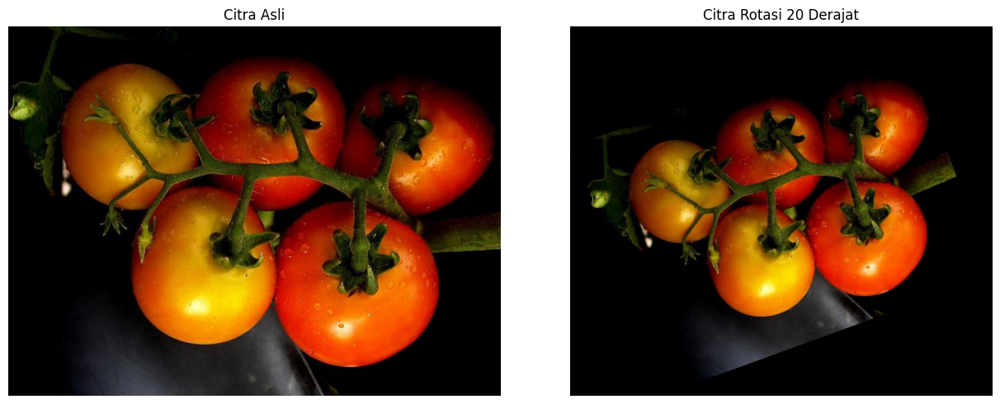

In [76]:
# 8.1 - ROTASI CITRA TOMAT SEBESAR 20 DERAJAT

nama_orb = "db_3_tomat_6buah.jpg"
img_asli_orb = images[nama_orb].copy()
sudut = 20

h, w = img_asli_orb.shape[:2]
pusat = (w / 2, h / 2)

# Membuat matriks rotasi
M = cv2.getRotationMatrix2D(
    pusat, sudut, 1.0
)

cos = abs(M[0, 0])
sin = abs(M[0, 1])

lebar_baru = int(np.ceil(h * sin + w * cos))
tinggi_baru = int(np.ceil(h * cos + w * sin))

M[0, 2] += lebar_baru / 2 - pusat[0]
M[1, 2] += tinggi_baru / 2 - pusat[1]

# Melakukan rotasi
img_rotasi_orb = cv2.warpAffine(
    img_asli_orb,
    M,
    (lebar_baru, tinggi_baru),
    flags=cv2.INTER_LINEAR,
    borderValue=(0, 0, 0)
)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].imshow(img_asli_orb)
ax[0].set_title("Citra Asli")

ax[1].imshow(img_rotasi_orb)
ax[1].set_title("Citra Rotasi 20 Derajat")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

Keypoint citra asli   : 1000
Keypoint citra rotasi : 1000
Ukuran descriptor asli: (1000, 32)
Ukuran descriptor rotasi: (1000, 32)


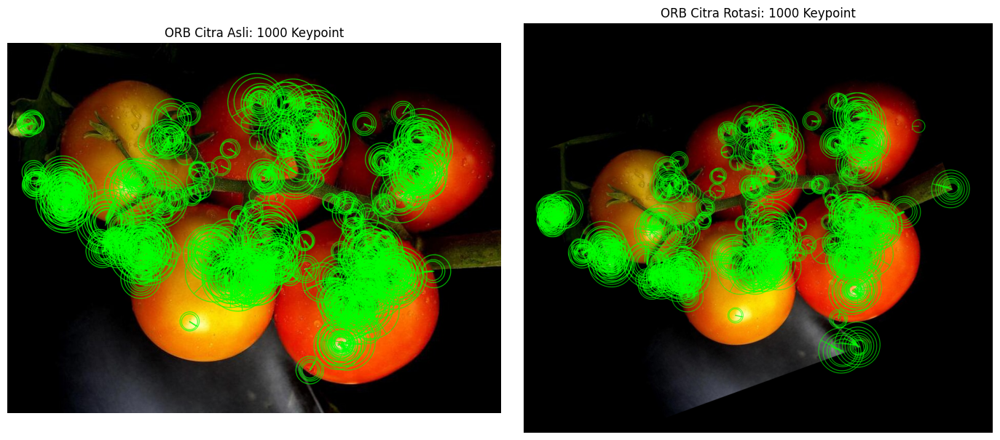

In [77]:
# 8.2 - DETEKSI KEYPOINT DAN DESCRIPTOR ORB

gray_asli = cv2.cvtColor(
    img_asli_orb,
    cv2.COLOR_RGB2GRAY
)

gray_rotasi = cv2.cvtColor(
    img_rotasi_orb,
    cv2.COLOR_RGB2GRAY
)

# Membuat ORB Detector dan Descriptor
orb = cv2.ORB_create(nfeatures=1000)

# Deteksi keypoint dan ekstraksi descriptor
kp_asli, des_asli = orb.detectAndCompute(
    gray_asli, None
)

kp_rotasi, des_rotasi = orb.detectAndCompute(
    gray_rotasi, None
)

print("Keypoint citra asli   :", len(kp_asli))
print("Keypoint citra rotasi :", len(kp_rotasi))

if des_asli is not None:
    print("Ukuran descriptor asli:", des_asli.shape)

if des_rotasi is not None:
    print("Ukuran descriptor rotasi:", des_rotasi.shape)

# Visualisasi keypoint
visual_asli = cv2.drawKeypoints(
    img_asli_orb,
    kp_asli,
    None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

visual_rotasi = cv2.drawKeypoints(
    img_rotasi_orb,
    kp_rotasi,
    None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(visual_asli)
ax[0].set_title(f"ORB Citra Asli: {len(kp_asli)} Keypoint")

ax[1].imshow(visual_rotasi)
ax[1].set_title(f"ORB Citra Rotasi: {len(kp_rotasi)} Keypoint")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

Keypoint citra asli   : 1000
Keypoint citra rotasi : 1000
Jumlah pasangan cocok : 700
Pasangan ditampilkan  : 30
Hamming Distance terkecil: 2.0


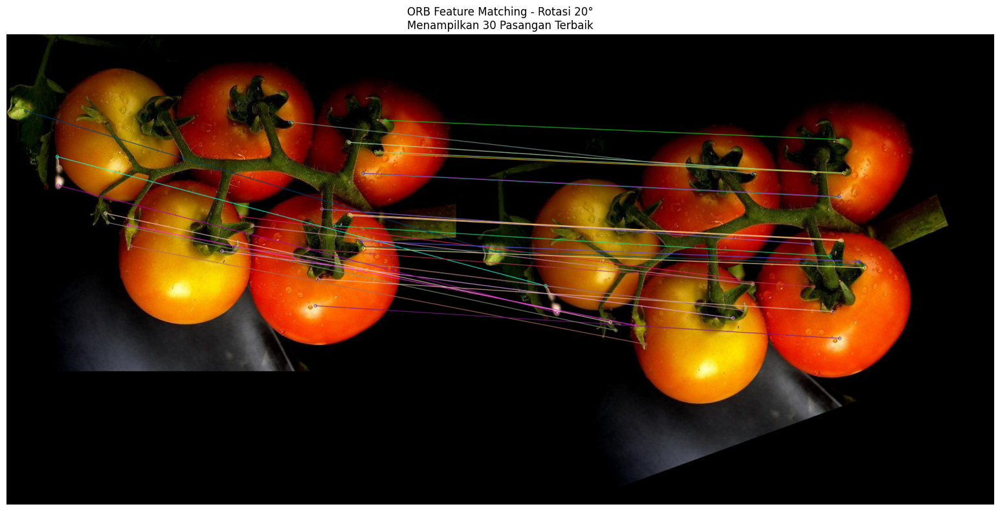

In [78]:
# 8.3 - FEATURE MATCHING MENGGUNAKAN BFMatcher

if des_asli is None or des_rotasi is None:
    raise ValueError("Descriptor ORB tidak ditemukan!")

# Membuat BFMatcher dengan Hamming Distance
bf = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=True
)

matches = bf.match(
    des_asli,
    des_rotasi
)

matches = sorted(
    matches,
    key=lambda x: x.distance
)

# Mengambil 30 pasangan terbaik
jumlah_tampil = min(30, len(matches))
matches_terbaik = matches[:jumlah_tampil]

print("Keypoint citra asli   :", len(kp_asli))
print("Keypoint citra rotasi :", len(kp_rotasi))
print("Jumlah pasangan cocok :", len(matches))
print("Pasangan ditampilkan  :", jumlah_tampil)

if len(matches) > 0:
    print(
        "Hamming Distance terkecil:",
        matches[0].distance
    )

hasil_matching = cv2.drawMatches(
    img_asli_orb,
    kp_asli,
    img_rotasi_orb,
    kp_rotasi,
    matches_terbaik,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(hasil_matching)
plt.title(
    f"ORB Feature Matching - Rotasi {sudut}°\n"
    f"Menampilkan {jumlah_tampil} Pasangan Terbaik"
)
plt.axis("off")
plt.tight_layout()
plt.show()

In [79]:
# 8.4 - RINGKASAN HASIL EKSPERIMEN ORB

print("Citra yang digunakan :", nama_orb)
print("Sudut rotasi         :", sudut, "derajat")
print("Metode               : ORB")
print("Matcher              : BFMatcher")
print("Jenis jarak          : Hamming Distance")
print()

print("Jumlah keypoint asli :", len(kp_asli))
print("Jumlah keypoint rotasi:", len(kp_rotasi))
print("Jumlah pasangan cocok:", len(matches))

if len(matches) > 0:
    rata_jarak = np.mean([m.distance for m in matches])

    print(f"Rata-rata Hamming Distance: {rata_jarak:.2f}")
    print()
    print("Kesimpulan:")
    print("Masih ditemukan pasangan keypoint setelah rotasi.")
else:
    print("Tidak ditemukan pasangan keypoint dengan konfigurasi ini.")

Citra yang digunakan : db_3_tomat_6buah.jpg
Sudut rotasi         : 20 derajat
Metode               : ORB
Matcher              : BFMatcher
Jenis jarak          : Hamming Distance

Jumlah keypoint asli : 1000
Jumlah keypoint rotasi: 1000
Jumlah pasangan cocok: 700
Rata-rata Hamming Distance: 18.84

Kesimpulan:
Masih ditemukan pasangan keypoint setelah rotasi.


# D. Analisis

Masih ditemukan 700 pasangan keypoint antara citra asli dan citra yang dirotasi sebesar 20 derajat, masih bisa ditemukan pasangan keypoint yang memiliki descriptor serupa meengguanakan BFMatcher dengan Hamming Distance. Ini menunjukan ORB mampu mempertahankan sebagian kecocokan fitur, meski orientasi citra berubah.

Fitru lokal dapat membantu mengenali citra yang mengalami rotasi melalu pencocokan bagian-bagian khas gambar.